# What does a small satellite's attitude-control design space say contends?

**A worked case for the posynomial invariant form** · Dynamical Systems Group · `hyperbolic_trade_space`

*Source:* [hyperbolic-trade-space](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space) (this notebook is `examples/adcs/adcs_trade_study.ipynb`)

*Stack:* Python · NumPy · SciPy · pandas · scikit-learn · matplotlib · the SysML v2 cubesat model of `examples/adcs/` (simulated once, cached)

A designer of a small satellite has a table of simulated designs and a question: what is it that cannot be had at the same time? This notebook follows one real trade study from the cached table to a fitted trade space, shows what the fit reports as contending, and only then explains it. The explanations are the author's and are marked as such; the reader's job, in the last section, is to judge them.

Start wherever suits you. The sections run in pipeline order (load, condition, fit, look, report, explain, predict, check) and each one ends by saying what the next one needs from it. The mathematics is in `docs/method.md` (lemma tags L1 to L10 are used below), conditioning in `docs/preconditioning.md`, the interface in `docs/api.md`, the limits of the method in `docs/limitations.md`.

**Cached data, no simulation.** This notebook reads four files in `data/` and nothing else: `adcs_designs_cubesat_gains.csv` (the primary dataset), `adcs_designs_cubesat.csv` (the regime comparison), `check_designs_cubesat.csv` and `check_predictions_cubesat.csv`. It does not simulate, does not regenerate any dataset and does not need the opensysml runtime. The executed outputs are committed with it; static copies of the figures are in `figures/`.


## 1 · The designer's question

You are choosing the attitude-control hardware and gains of a cubesat. The satellite must turn through 30 degrees within a 600 s horizon and then hold its pointing. You choose the reaction-wheel class (small, medium, large), the star-tracker grade (coarse, medium, fine), the solar-panel span, the battery capacity and two controller gains, Kp and Kd.

The questions a designer asks are physical. What does a faster slew cost? What does sharper pointing cost, in mass and in power? What does a bigger wheel do to the rest of the bus? And do the answers change if the control loop is driven harder? A thousand designs were sampled over these choices and each was simulated once, with the SysML v2 model providing the accounting (masses, power, wheel capacities). A table of ten attributes per design is the result. A trade study usually reads such a table by eye, or sorts it by one column.

Here the table is asked a different question: which of the ten attributes jointly bind the best designs, and which merely move together? The answer is not assumed. No tension is named in this notebook until the fitted model reports one (section 7), and what the report found is explained only after that (section 9).


### Notation quickstart

Each symbol is defined again where it first does work; this table is the short version.

| Symbol | Meaning | Where |
|---|---|---|
| attribute $a_j$ | a raw column of the table (seconds, kilograms, watt-hours); ten of them | 2 |
| orientation $o_j$ | $-1$ if smaller is better (the column is taken reciprocally), $+1$ if larger is better | 3 |
| metric $m_j$ | the conditioned attribute: strictly positive, larger is better, unit log-spread (assumption A4) | 3 |
| $u=\log m$ | log-metrics; the model is linear in $u$ | 4 |
| exponents $w$ | non-negative weights summing to one (A2); where the weight is large, the metric binds | 4 |
| $V=\exp(w\cdot u-\beta)$ | invariant value of a design; $V=1$ is the fitted frontier, $V\le1$ is attainable (L1) | 4 |
| temperature $\tau$ | softness of the maximum in the fit; units of inverse log-spread; $\tau=\infty$ is the exact maximum (L5) | 4 |
| band $1/\tau$ | half-width in $\log V$ of the near-frontier designs | 4 |
| chart $Z$ | $d-1$ log-ratio coordinates giving position along the frontier; $[Z\mid\log V]$ is an invertible chart of the metrics (L8) | 6 |
| contending set | the metrics with positive exponent at $\tau=\infty$; any size, not chosen in advance | 7 |
| novelty $V-1$ | how far beyond the learned frontier a design lies; calibrated novelty is its rank among the training designs and $\tau\log V$ | 11 |
| improvement factor | the factor on one metric alone that lands a design on $V=1$ (L7) | 11 |


In [1]:
# CELL: setup
# ruff: noqa: E501
# The visual vocabulary is the plotting module's; it is documented here once and never changed.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
from sklearn.compose import ColumnTransformer
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder

from hyperbolic_trade_space import (
    HyperbolicTradeSpace,
    LogAffinePreconditioner,
    TradeSpaceRegressor,
    frontier_in_original_units,
    select_temperature,
    tension_report,
)
from hyperbolic_trade_space.gaps import find_holes, frontier_targets
from hyperbolic_trade_space.plotting import (
    BAND_COLOR,
    CATEGORY_COLORS,
    DATA_COLOR,
    FRONTIER_COLOR,
    HOLE_COLOR,
    TENSION_CMAP,
    plot_frontier_coordinates,
    plot_frontier_surface_3d,
    plot_log_plane,
    plot_tensions,
    plot_v_by_variable,
)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.grid": False, "font.size": 9})
DATA, FIGS = Path("data"), Path("figures")
FIGS.mkdir(exist_ok=True)
MEASURED_COLOR = CATEGORY_COLORS[3]  # the one addition to the vocabulary: measured check designs


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


print("visual vocabulary (hyperbolic_trade_space.plotting):")
print(f"  frontier V = 1          {FRONTIER_COLOR} (line, plane or wireframe)")
print(
    f"  near-frontier band      {BAND_COLOR} (grey strip; points inside the band ringed in black)"
)
print(f"  holes (white space)     vermillion {HOLE_COLOR}")
print("  targets                 open markers, black edge")
print(f"  plain data              blue {DATA_COLOR}")
print(f"  categories (wheel class) {CATEGORY_COLORS[:3]} in label order 1 small, 2 medium, 3 large")
print(
    f"  tension map             {TENSION_CMAP}: negative association (tension) to positive (aligned)"
)
print(f"  measured check designs  {MEASURED_COLOR} filled diamonds (added here; no other meaning)")

visual vocabulary (hyperbolic_trade_space.plotting):
  frontier V = 1          black (line, plane or wireframe)
  near-frontier band      0.7 (grey strip; points inside the band ringed in black)
  holes (white space)     vermillion #D55E00
  targets                 open markers, black edge
  plain data              blue #0072B2
  categories (wheel class) ('#0072B2', '#E69F00', '#009E73') in label order 1 small, 2 medium, 3 large
  tension map             PuOr: negative association (tension) to positive (aligned)
  measured check designs  #CC79A7 filled diamonds (added here; no other meaning)


In [2]:
# CELL: names
ATTRS = [
    "settling_time_s",
    "slew_time_s",
    "pointing_error_deg",
    "total_mass_kg",
    "control_effort",
    "power_margin_w",
    "energy_balance_wh",
    "eclipse_reserve_wh",
    "peak_slew_power_w",
    "dod_eclipse",
]
SHORT = {
    "settling_time_s": "settling time",
    "slew_time_s": "slew time",
    "pointing_error_deg": "pointing error",
    "total_mass_kg": "total mass",
    "control_effort": "control effort",
    "power_margin_w": "power margin",
    "energy_balance_wh": "energy balance",
    "eclipse_reserve_wh": "eclipse reserve",
    "peak_slew_power_w": "peak slew power",
    "dod_eclipse": "depth of discharge",
}
UNITS = {
    "settling_time_s": "s",
    "slew_time_s": "s",
    "pointing_error_deg": "deg",
    "total_mass_kg": "kg",
    "control_effort": "(torque.s, proxy)",
    "power_margin_w": "W",
    "energy_balance_wh": "Wh",
    "eclipse_reserve_wh": "Wh",
    "peak_slew_power_w": "W",
    "dod_eclipse": "fraction",
}
# -1: smaller is better (reciprocal); +1: larger is better (direct)
ORIENT = {
    "settling_time_s": -1,
    "slew_time_s": -1,
    "pointing_error_deg": -1,
    "total_mass_kg": -1,
    "control_effort": -1,
    "power_margin_w": +1,
    "energy_balance_wh": +1,
    "eclipse_reserve_wh": +1,
    "peak_slew_power_w": -1,
    "dod_eclipse": -1,
}
WHEELS, TRACKERS = ["small", "medium", "large"], ["coarse", "medium", "fine"]
WHEEL_LABEL = {"small": "1 small", "medium": "2 medium", "large": "3 large"}
DESIGN_VARS = ["panel_span_m", "battery_wh", "Kp", "Kd"]
MODEL_RANGES = {
    "panel_span_m": (0.3, 1.0),
    "battery_wh": (20.0, 200.0),
    "Kp": (0.2, 2.0),
    "Kd": (0.3, 1.5),
}
print("ten attributes (orientation: -1 smaller is better, +1 larger is better):")
print("  " + "; ".join(f"{SHORT[a]} ({UNITS[a]}, {ORIENT[a]:+d})" for a in ATTRS))
print(
    "covariates: wheel class " + " < ".join(WHEELS) + "; star-tracker grade " + " < ".join(TRACKERS)
)
print("design variables: " + ", ".join(DESIGN_VARS))


def short_label(a):
    """Compact conditioned-axis label with unit, for crowded 3-D axes (larger is better is stated in the title)."""
    return f"conditioned {SHORT[a]} ({'1/' if ORIENT[a] < 0 else ''}{UNITS[a].strip('()')})"


def cond_label(a):
    """Axis label of a conditioned metric, in attribute terms (never a bare unit)."""
    return (
        f"conditioned {SHORT[a]} (inverse {UNITS[a].strip('()')}; larger is better)"
        if ORIENT[a] < 0
        else f"conditioned {SHORT[a]} ({UNITS[a]}; larger is better)"
    )

ten attributes (orientation: -1 smaller is better, +1 larger is better):
  settling time (s, -1); slew time (s, -1); pointing error (deg, -1); total mass (kg, -1); control effort ((torque.s, proxy), -1); power margin (W, +1); energy balance (Wh, +1); eclipse reserve (Wh, +1); peak slew power (W, -1); depth of discharge (fraction, -1)
covariates: wheel class small < medium < large; star-tracker grade coarse < medium < fine
design variables: panel_span_m, battery_wh, Kp, Kd


In [3]:
# CELL: load
raw = pd.read_csv(DATA / "adcs_designs_cubesat_gains.csv")
print("read from data/adcs_designs_cubesat_gains.csv (cached; written once by generate_dataset.py;")
print("nothing is simulated or regenerated in this notebook)")
print(
    f"{len(raw)} designs, {raw.shape[1]} columns; scenario: {raw.slew_deg.iloc[0]} deg slew, "
    f"{raw.t_end_s.iloc[0]} s horizon, {raw.seed.nunique()} distinct per-design seeds"
)
print(
    f"gain box: Kp {raw.Kp.min():.2f} to {raw.Kp.max():.2f}, Kd {raw.Kd.min():.2f} to {raw.Kd.max():.2f}; "
    f"median Kd/Kp {np.median(raw.Kd / raw.Kp):.2f}"
)
cols = ["wheel_class", "st_grade", *DESIGN_VARS]
print(
    raw[cols]
    .describe(include="all")
    .loc[["count", "unique", "top", "freq", "min", "max"]]
    .T.to_string()
)

read from data/adcs_designs_cubesat_gains.csv (cached; written once by generate_dataset.py;
nothing is simulated or regenerated in this notebook)
1000 designs, 35 columns; scenario: 30 deg slew, 600 s horizon, 1000 distinct per-design seeds
gain box: Kp 0.20 to 2.00, Kd 0.30 to 1.50; median Kd/Kp 1.06
               count unique     top freq        min         max
wheel_class     1000      3  medium  345        NaN         NaN
st_grade        1000      3  coarse  347        NaN         NaN
panel_span_m  1000.0    NaN     NaN  NaN   0.300612    0.999191
battery_wh    1000.0    NaN     NaN  NaN  20.023366  199.770957
Kp            1000.0    NaN     NaN  NaN     0.2005    1.998724
Kd            1000.0    NaN     NaN  NaN   0.300144    1.499549


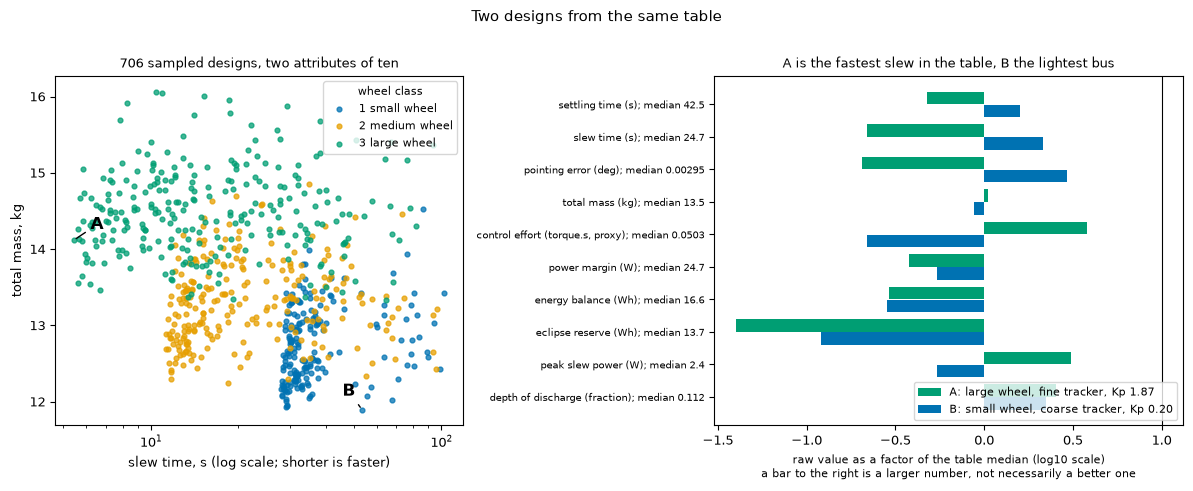

A: slew time 5.4 s, total mass 14.1 kg, control effort 0.190, pointing error 0.0006 deg
B: slew time 53.2 s, total mass 11.9 kg, control effort 0.011, pointing error 0.0086 deg


In [4]:
# CELL: hook-figure
# Two designs of the table, picked by one column each, and where they sit among the others.
okmask = raw.settled & raw.power_ok & raw.momentum_ok & (raw[ATTRS] > 0).all(axis=1)
hook = raw[okmask].reset_index(drop=True)  # the designs that section 2 will define as feasible
iA, iB = hook.slew_time_s.idxmin(), hook.total_mass_kg.idxmin()
DA, DB = hook.loc[iA], hook.loc[iB]
colA, colB = (
    CATEGORY_COLORS[WHEELS.index(DA.wheel_class)],
    CATEGORY_COLORS[WHEELS.index(DB.wheel_class)],
)
fig, (axl, axr) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})
for k, w in enumerate(WHEELS):
    s = hook[hook.wheel_class == w]
    axl.scatter(
        s.slew_time_s,
        s.total_mass_kg,
        s=12,
        color=CATEGORY_COLORS[k],
        alpha=0.75,
        label=WHEEL_LABEL[w] + " wheel",
    )
axl.set_xscale("log")
axl.set_xlabel("slew time, s (log scale; shorter is faster)")
axl.set_ylabel("total mass, kg")
axl.legend(fontsize=8, title="wheel class", title_fontsize=8, loc="upper right")
for D, lab, off in [(DA, "A", (12, 8)), (DB, "B", (-14, 10))]:
    axl.annotate(
        lab,
        (D.slew_time_s, D.total_mass_kg),
        xytext=off,
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        arrowprops={"arrowstyle": "-", "color": "black"},
    )
axl.set_title(f"{len(hook)} sampled designs, two attributes of ten", fontsize=9)
med = hook[ATTRS].median()
ypos = np.arange(len(ATTRS))[::-1]
axr.axvline(1.0, color=FRONTIER_COLOR, lw=0.8)
for D, lab, col, dy in [(DA, "A", colA, 0.2), (DB, "B", colB, -0.2)]:
    fac = (D[ATTRS].astype(float) / med).to_numpy()
    axr.barh(
        ypos + dy,
        np.log10(fac),
        height=0.38,
        color=col,
        label=f"{lab}: {D.wheel_class} wheel, {D.st_grade} tracker, Kp {D.Kp:.2f}",
    )
axr.set_yticks(
    ypos,
    [f"{SHORT[a]} ({UNITS[a].strip(chr(40) + chr(41))}); median {med[a]:.3g}" for a in ATTRS],
    fontsize=7,
)
axr.set_xlabel(
    "raw value as a factor of the table median (log10 scale)\na bar to the right is a larger number, not necessarily a better one"
)
axr.xaxis.label.set_size(8)
axr.legend(fontsize=8, loc="lower right")
axr.set_title("A is the fastest slew in the table, B the lightest bus", fontsize=9)
fig.suptitle("Two designs from the same table", y=1.01)
save(fig, "01_two_designs")
print(
    f"A: slew time {DA.slew_time_s:.1f} s, total mass {DA.total_mass_kg:.1f} kg, control effort {DA.control_effort:.3f}, pointing error {DA.pointing_error_deg:.4f} deg"
)
print(
    f"B: slew time {DB.slew_time_s:.1f} s, total mass {DB.total_mass_kg:.1f} kg, control effort {DB.control_effort:.3f}, pointing error {DB.pointing_error_deg:.4f} deg"
)

Two designs of the same table, each picked by one column: A has the shortest slew time (5.4 s) and B the lowest total mass (11.9 kg). They differ in more than those two attributes: A has a large wheel and a fine tracker, B a small wheel and a coarse tracker, and A spends about seventeen times the control effort of B. Neither is the better design. A designer reading the table by eye would sort by a column, find A or B, and wonder what else came with it. That is the question this notebook asks of all ten attributes at once, with the machinery of the posynomial invariant form instead of by eye. Before anything can be fitted the table must say which designs count (section 2) and what "better" means for each column (section 3).

## 2 · Load the designs and define the feasible set

A design counts only if its simulation settled before the horizon (the `settled` flag; slew and settling times are censored at 600 s otherwise), its power budget held (`power_ok`) and its wheel momentum stayed within the wheel's capacity (`momentum_ok`; momentum is enforced as a feasibility condition, not used as a metric). A design must also have all ten attributes positive, because the conditioning takes logarithms. The depth-of-discharge flag `dod_ok` is reported but is not a filter: depth of discharge is itself a metric.


In [5]:
# CELL: feasible
pos = (raw[ATTRS] > 0).all(axis=1)
checks = {
    "settled": raw.settled,
    "power_ok": raw.power_ok,
    "momentum_ok": raw.momentum_ok,
    "all ten attributes positive": pos,
}
rows, alive = [], pd.Series(True, index=raw.index)
for name, ok in checks.items():
    newly = int((alive & ~ok).sum())
    alive &= ok
    rows.append(
        {
            "condition": name,
            "fails alone": int((~ok).sum()),
            "removed in this order": newly,
            "remaining": int(alive.sum()),
        }
    )
print(pd.DataFrame(rows).to_string(index=False))
feasible = raw[alive].reset_index(drop=True)
print(f"\nfeasible: {len(feasible)} of {len(raw)} designs")
print("by wheel class (feasible / all, share failing momentum_ok):")
for w in WHEELS:
    n_all, n_ok = int((raw.wheel_class == w).sum()), int((feasible.wheel_class == w).sum())
    fail_mom = 1 - raw.loc[raw.wheel_class == w, "momentum_ok"].mean()
    print(f"  {w:7s} {n_ok:4d} / {n_all:4d}   momentum failures {fail_mom:5.1%}")
print(
    f"\ndod_ok is reported, not used as a filter: false for {int((~raw.dod_ok).sum())} designs overall "
    f"and {int((~feasible.dod_ok).sum())} of the feasible set;"
)
print(
    f"a violated dod_ok coincides with a non-positive eclipse reserve "
    f"({int(((raw.eclipse_reserve_wh <= 0) == ~raw.dod_ok).sum())} of 1000 agree), so those designs leave "
    "through the positivity condition above, and depth of discharge stays a metric."
)
print(f"power_ok is true for every design ({int(raw.power_ok.sum())} of 1000).")
print(
    f"settled false: {int((~raw.settled).sum())} designs (their times are censored at the horizon)."
)

                  condition  fails alone  removed in this order  remaining
                    settled           24                     24        976
                   power_ok            0                      0        976
                momentum_ok          188                    165        811
all ten attributes positive          131                    105        706

feasible: 706 of 1000 designs
by wheel class (feasible / all, share failing momentum_ok):
  small    191 /  344   momentum failures 37.2%
  medium   248 /  345   momentum failures 17.4%
  large    267 /  311   momentum failures  0.0%

dod_ok is reported, not used as a filter: false for 131 designs overall and 0 of the feasible set;
a violated dod_ok coincides with a non-positive eclipse reserve (1000 of 1000 agree), so those designs leave through the positivity condition above, and depth of discharge stays a metric.
power_ok is true for every design (1000 of 1000).
settled false: 24 designs (their times are censored 

**What the output shows.** Of 1000 designs 706 are feasible (small wheels 191, medium 248, large 267). Momentum alone removes 188 designs, and it falls on the wheels unevenly: 37.2 % of small-wheel designs and 17.4 % of medium-wheel designs fail it, large wheels never. `power_ok` removes nothing. All 131 designs with `dod_ok` false have a non-positive eclipse reserve, so they leave through the positivity condition and none of them is in the feasible set. The wheel class is therefore already visible as a feasibility boundary before any model is fitted.

*Next:* the fit needs strictly positive, larger-is-better metrics on a comparable scale.


## 3 · Conditioning

Conditioning turns attributes into metrics. For each of the ten attributes $a_j$ the preconditioner computes $z_j=o_j\log a_j$, with orientation $o_j=-1$ (reciprocal) for settling time, slew time, pointing error, total mass, control effort, peak slew power and depth of discharge, and $o_j=+1$ (direct) for power margin, energy balance and eclipse reserve. It then scales each $z_j$ to unit standard deviation (`scaler="standard"`) and exponentiates, giving the metric $m_j$. This is the log-affine conditioning of assumption A4; the map is invertible and the fitted frontier can be pulled back to attribute units (L9, section 12).

The two categorical covariates go through an `OrdinalEncoder` with explicit category orders (wheel small < medium < large; tracker coarse < medium < fine) and the four continuous design variables pass through, all inside one `ColumnTransformer`. The covariates are not metrics; they are kept next to the metrics so that later sections can colour and group by them.

Conditioning is a choice of question, not a nuisance step (`docs/preconditioning.md`): the units of the temperature, and which facet the fit finds, depend on it. The choice is probed in section 8.


In [6]:
# CELL: conditioning
def make_conditioner(attrs, scaler="standard"):
    """ColumnTransformer: attributes -> metrics; covariates -> ordinal codes; design variables pass."""
    return ColumnTransformer(
        [
            (
                "metrics",
                LogAffinePreconditioner(orientation=[ORIENT[a] for a in attrs], scaler=scaler),
                list(attrs),
            ),
            (
                "covariates",
                OrdinalEncoder(categories=[WHEELS, TRACKERS]),
                ["wheel_class", "st_grade"],
            ),
            ("design", "passthrough", DESIGN_VARS),
        ],
        verbose_feature_names_out=True,
    ).set_output(transform="pandas")


cond = make_conditioner(ATTRS)
table = cond.fit_transform(feasible)
M = table[[f"metrics__{a}" for a in ATTRS]].to_numpy()
pre = cond.named_transformers_["metrics"]
print(
    "columns of the conditioned table:",
    ", ".join(table.columns[:2].tolist()),
    "...",
    table.columns[-1],
)
print(
    f"metrics matrix M: {M.shape}, all strictly positive: {bool((M > 0).all())}, larger is better"
)
out = pd.DataFrame(
    {
        "orientation": ["reciprocal" if ORIENT[a] < 0 else "direct" for a in ATTRS],
        "raw min": feasible[ATTRS].min().to_numpy(),
        "raw max": feasible[ATTRS].max().to_numpy(),
        "log-spread k": pre.log_scale_,
        "std of log m": np.log(M).std(axis=0),
        "m min": M.min(axis=0),
        "m max": M.max(axis=0),
    },
    index=[SHORT[a] for a in ATTRS],
)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print(out.to_string())
back = pre.inverse_transform(M)
print(
    f"\ninverse_transform recovers the attributes: max relative error {np.max(np.abs(back / feasible[ATTRS].to_numpy() - 1)):.1e}"
)

columns of the conditioned table: metrics__settling_time_s, metrics__slew_time_s ... design__Kd
metrics matrix M: (706, 10), all strictly positive: True, larger is better
                   orientation   raw min  raw max  log-spread k  std of log m    m min  m max
settling time       reciprocal     7.322    505.9        0.8282             1  0.05526  9.194
slew time           reciprocal     5.427    102.3        0.6455             1  0.09328  8.829
pointing error      reciprocal 0.0006016 0.008639        0.8604             1   0.3139  6.946
total mass          reciprocal      11.9    16.06       0.06581             1  0.07706  7.388
control effort      reciprocal  0.008614   0.3449         0.745             1  0.07332  10.38
power margin            direct     6.866    65.85        0.5133             1  0.08544  6.992
energy balance          direct     1.186     55.9        0.8275             1  0.04783  5.033
eclipse reserve         direct  0.008278    51.95         1.305             1

**What the output shows.** Every conditioned metric has log-standard-deviation exactly 1, by construction; the column "log-spread k" gives the log-units behind one unit. The spreads differ a great deal. Total mass varies only from 11.9 to 16.1 kg, so $k=0.066$: one unit of the mass metric is a 6.8 % change in kilograms. Eclipse reserve ranges over more than three orders of magnitude and has $k=1.31$. The model treats one unit of log-spread of any metric as the same amount of "better"; this is what unit log-spread means and it is a modelling choice. The inverse transform recovers the attributes to rounding error.

*Next:* a temperature and a fit on the ten metrics.


## 4 · Temperature, fit and diagnostics

The model is a single monomial in the metrics, $V(m)=\exp(w\cdot\log m-\beta)$ with exponents $w$ on the simplex (assumptions A1, A2; L1). It is fitted by minimising a soft maximum of the scores $w\cdot u_i$ (the log-mean-exp at temperature $\tau$, L5), so the optimal $w$ puts weight on the metrics that most limit how far the best designs can go together. At $\tau=\infty$ this is a linear program whose solution is generally sparse; at finite $\tau$ the weights are smoothed.

The temperature is chosen, not tuned to a result: `select_temperature(M, target_frac_above=0.10, bounds=(3, 1e3))` finds the $\tau$ at which a tenth of the designs lie above $V=1$. The lower bound 3 keeps the search inside the documented useful range; below about $\tau=3$ the fraction above is not monotone (`docs/api.md`).


In [7]:
# CELL: temperature
def fit_space(M, target=0.10, bounds=(3, 1e3)):
    tau = select_temperature(M, target_frac_above=target, bounds=bounds)
    return tau, HyperbolicTradeSpace(temperature=tau).fit(M)


tau, est = fit_space(M)
diag = pd.DataFrame({"metric": [SHORT[a] for a in ATTRS], "exponent w": est.exponents_[0]})
print(diag.to_string(index=False))
print(
    f"\ntau = {tau:.2f}   target frac_above = 0.10   fitted frac_above_ = {est.frac_above_:.3f}   "
    f"n_eff_ = {est.n_eff_:.1f} of {len(M)}   objective_ = {est.objective_:.4f}   "
    f"log_offset_ = {est.log_offset_[0]:.4f}   band 1/tau = {1 / tau:.4f}"
)
print(f"sum of exponents = {est.exponents_[0].sum():.6f} (A2)")

            metric  exponent w
     settling time           0
         slew time      0.2395
    pointing error      0.1022
        total mass      0.1796
    control effort      0.1974
      power margin    3.53e-17
    energy balance      0.1902
   eclipse reserve   5.631e-17
   peak slew power           0
depth of discharge     0.09107

tau = 38.10   target frac_above = 0.10   fitted frac_above_ = 0.096   n_eff_ = 16.2 of 706   objective_ = 0.2036   log_offset_ = 0.2036   band 1/tau = 0.0262
sum of exponents = 1.000000 (A2)


**What the output shows.** The target is met: $\tau=38.1$, `frac_above_` $=0.096$ against 0.10. Six of the ten metrics carry exponent above $10^{-3}$ (slew time 0.240, control effort 0.197, energy balance 0.190, total mass 0.180, pointing error 0.102, depth of discharge 0.091); settling time, power margin, eclipse reserve and peak slew power carry none at this temperature. The effective sample size is `n_eff_` $=16.2$ of 706 designs: at this temperature the fit rests on a small number of designs, which is a limit of the result and is repeated in section 15. The band $1/\tau$ is 0.026 in $\log V$.


### The temperature sweep

The same fit across twelve temperatures on a log grid in $(3,10^3)$ and at $\tau=\infty$, then a few temperatures below the useful range, shown and not used.


  tau  frac_above  n_eff  metrics with w>1e-3  largest w largest at
    3      0.4533  588.8                    6      0.244  slew time
5.087      0.4037  462.1                    6      0.246  slew time
8.626      0.3314    291                    6     0.2476  slew time
14.63      0.2436  137.7                    6     0.2483  slew time
 24.8      0.1558   46.9                    6     0.2462  slew time
42.06     0.08499  12.79                    6      0.237  slew time
71.32     0.04533  5.332                    6     0.2196  slew time
120.9     0.02266  3.959                    6     0.2114 total mass
205.1     0.01558  3.573                    6     0.2192 total mass
347.8     0.01275  3.346                    6     0.2215 total mass
589.7     0.01133  3.229                    6      0.222 total mass
 1000    0.009915  3.197                    6     0.2222 total mass
  inf           0  3.191                    6     0.2228 total mass



below the useful range (tau < 3, outside the documented range; shown, not used):
 tau  frac_above  n_eff
 0.1      0.5397  705.8
 0.3      0.5368  704.3
   1      0.5184  688.7
   3      0.4533  588.8


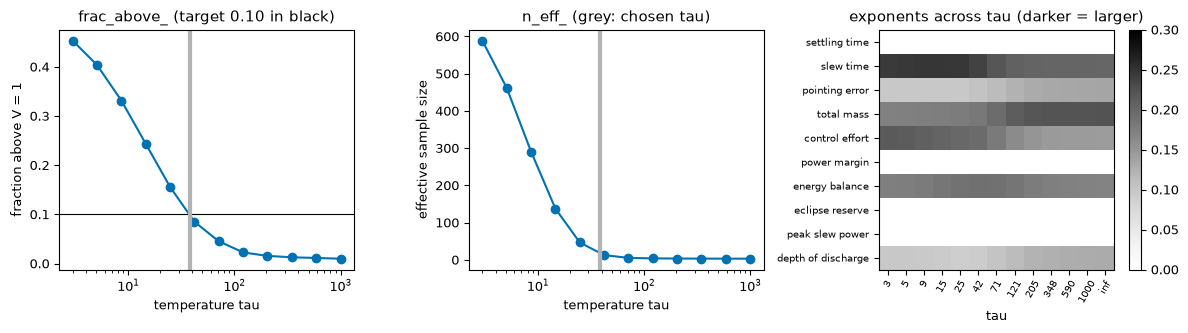

In [8]:
# CELL: sweep
grid = [*np.geomspace(3, 1e3, 12), np.inf]
rows = []
for t in grid:
    e = HyperbolicTradeSpace(temperature=t).fit(M)
    w = e.exponents_[0]
    rows.append(
        {
            "tau": t,
            "frac_above": e.frac_above_,
            "n_eff": e.n_eff_,
            "metrics with w>1e-3": int((w > 1e-3).sum()),
            "largest w": w.max(),
            "largest at": SHORT[ATTRS[int(w.argmax())]],
        }
    )
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))
small = []
for t in [0.1, 0.3, 1.0, 3.0]:
    e = HyperbolicTradeSpace(temperature=t).fit(M)
    small.append({"tau": t, "frac_above": e.frac_above_, "n_eff": e.n_eff_})
print("\nbelow the useful range (tau < 3, outside the documented range; shown, not used):")
print(pd.DataFrame(small).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
fin = sweep[np.isfinite(sweep.tau)]
axes[0].semilogx(fin.tau, fin.frac_above, "o-", color=DATA_COLOR)
axes[0].axhline(0.10, color=FRONTIER_COLOR, lw=0.8)
axes[0].axvline(tau, color=BAND_COLOR, lw=3)
axes[0].set(
    xlabel="temperature tau",
    ylabel="fraction above V = 1",
    title="frac_above_ (target 0.10 in black)",
)
axes[1].semilogx(fin.tau, fin.n_eff, "o-", color=DATA_COLOR)
axes[1].axvline(tau, color=BAND_COLOR, lw=3)
axes[1].set(
    xlabel="temperature tau", ylabel="effective sample size", title="n_eff_ (grey: chosen tau)"
)
W = np.array([HyperbolicTradeSpace(temperature=t).fit(M).exponents_[0] for t in grid])
im = axes[2].imshow(W.T, cmap="Greys", aspect="auto", vmin=0, vmax=0.3)
axes[2].set_xticks(
    range(len(grid)),
    [f"{t:.0f}" if np.isfinite(t) else "inf" for t in grid],
    rotation=60,
    fontsize=7,
)
axes[2].set_yticks(range(len(ATTRS)), [SHORT[a] for a in ATTRS], fontsize=7)
axes[2].set(xlabel="tau", title="exponents across tau (darker = larger)")
fig.colorbar(im, ax=axes[2])
save(fig, "02_tau_sweep")

**What the output shows.** Over the useful range the fraction above the frontier falls steadily from 0.45 at $\tau=3$ to 0.010 at $\tau=1000$ and 0 at $\tau=\infty$, and the effective sample size falls from 589 to 3.2: a harder maximum rests on fewer designs (L5). The same six metrics carry exponent over the whole range; the largest exponent is slew time up to $\tau=71$ and total mass from $\tau=121$. Below the useful range the response is flat and does not fall: `frac_above_` is 0.54 at $\tau=0.1$ and 0.3, 0.52 at 1 and 0.45 at 3, because the soft maximum approaches the mean of the scores (L5) and the fraction above the frontier stays near one half. That region is outside the documented range; the notebook does not use it.

*Next:* what the fitted surface looks like. A ten-metric frontier cannot be drawn, so the next sections draw chosen views of it.


## 5 · The frontier in figures

Two kinds of view are used, and the notebook says which. **Subset views** refit the model on three chosen metrics so that the surface $V=1$ can be drawn in three dimensions; they are separate fits, each with its own conditioning and temperature, and they ignore the other seven metrics. The two subsets (the defaults of the study design) are slew time, pointing error and control effort, and total mass, eclipse reserve and power margin. **Slices** of the full ten-metric fit are two-dimensional cuts: the fitted exponents of two metrics renormalised to sum to one, with the other eight metrics held at their near-frontier median.

*Visual vocabulary* (printed in the first cell and used throughout): frontier black, near-frontier band grey, holes vermillion, targets open markers, one qualitative palette for categories (here always the wheel class: 1 small, 2 medium, 3 large), a diverging map for association. Axes are the conditioned metrics, larger is better; the label says so and gives the attribute and its unit (inverted, for attributes that were smaller-is-better).


slew time, pointing error, control effort: n = 706, tau = 15.37, exponents [0.45  0.044 0.507], share on or beyond the surface 0.106, share within the band 0.106; edge-on view on control effort: largest gap below the line among near-frontier designs 0.116 (log units)
total mass, eclipse reserve, power margin: n = 706, tau = 18.43, exponents [0.389 0.337 0.274], share on or beyond the surface 0.102, share within the band 0.082; edge-on view on total mass: largest gap below the line among near-frontier designs 0.138 (log units)


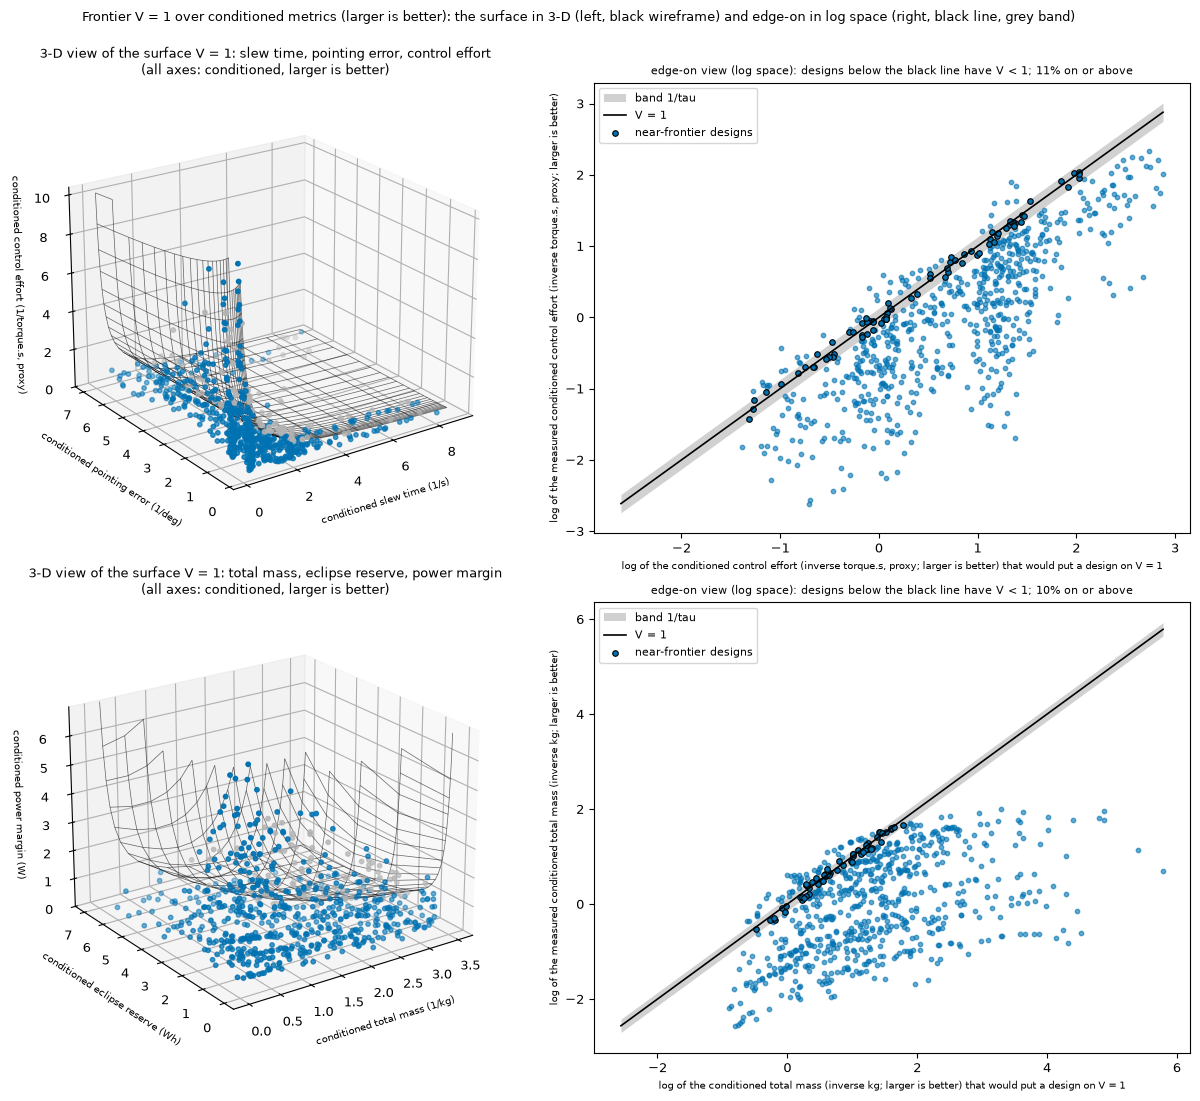

In [9]:
# CELL: surfaces
def subset_fit(frame, attrs):
    c = make_conditioner(attrs)
    t = c.fit_transform(frame)
    Ms = t[[f"metrics__{a}" for a in attrs]].to_numpy()
    tau_s, e = fit_space(Ms)
    return c, Ms, tau_s, e


SUBSETS = {
    "slew time, pointing error, control effort": [
        "slew_time_s",
        "pointing_error_deg",
        "control_effort",
    ],
    "total mass, eclipse reserve, power margin": [
        "total_mass_kg",
        "eclipse_reserve_wh",
        "power_margin_w",
    ],
}
sub_fits = {}
fig = plt.figure(figsize=(12.5, 11))
for k, (title, attrs) in enumerate(SUBSETS.items()):
    c3, M3, tau3, e3 = subset_fit(feasible, attrs)
    sub_fits[title] = (c3, M3, tau3, e3)
    w3, beta3 = e3.exponents_[0], e3.log_offset_[0]
    z = int(np.argmax(w3))
    x, y = [j for j in range(3) if j != z]
    lv3 = e3.score_samples(M3)
    near3 = np.abs(lv3) < 1 / tau3
    # left: the surface V = 1 in the conditioned metrics themselves (3-D)
    ax = fig.add_subplot(2, 2, 2 * k + 1, projection="3d")
    plot_frontier_surface_3d(e3, M3, ax=ax)
    ax.set_xlabel(short_label(attrs[0]), fontsize=7, labelpad=6)
    ax.set_ylabel(short_label(attrs[1]), fontsize=7, labelpad=6)
    ax.set_zlabel(short_label(attrs[2]), fontsize=7, labelpad=2)
    ax.set_zlim(0, M3.max(axis=0)[2])
    ax.set_title(
        f"3-D view of the surface V = 1: {title}\n(all axes: conditioned, larger is better)",
        fontsize=9,
    )
    ax.view_init(elev=22, azim=-125)
    # right: the same surface seen edge-on in log space; every design against the height of V = 1 above it
    ax2 = fig.add_subplot(2, 2, 2 * k + 2)
    U3 = np.log(M3)
    h = (beta3 - w3[x] * U3[:, x] - w3[y] * U3[:, y]) / w3[
        z
    ]  # log height of V = 1 above each design
    assert np.allclose(lv3, w3[z] * (U3[:, z] - h))
    lo, hi = min(h.min(), U3[:, z].min()), max(h.max(), U3[:, z].max())
    d = np.array([lo, hi])
    ax2.fill_between(
        d,
        d - 1 / (tau3 * w3[z]),
        d + 1 / (tau3 * w3[z]),
        color=BAND_COLOR,
        alpha=0.6,
        lw=0,
        label="band 1/tau",
    )
    ax2.plot(d, d, color=FRONTIER_COLOR, lw=1.2, label="V = 1")
    ax2.scatter(h[~near3], U3[~near3, z], s=10, color=DATA_COLOR, alpha=0.6)
    ax2.scatter(
        h[near3],
        U3[near3, z],
        s=16,
        color=DATA_COLOR,
        edgecolor="black",
        linewidth=0.8,
        label="near-frontier designs",
    )
    ax2.set_xlabel(
        f"log of the {cond_label(attrs[z])} that would put a design on V = 1", fontsize=7
    )
    ax2.set_ylabel(f"log of the measured {cond_label(attrs[z])}", fontsize=7)
    ax2.set_title(
        f"edge-on view (log space): designs below the black line have V < 1; {np.mean(lv3 >= 0):.0%} on or above",
        fontsize=8,
    )
    ax2.legend(fontsize=8, loc="upper left")
    print(
        f"{title}: n = {len(M3)}, tau = {tau3:.2f}, exponents {np.round(w3, 3)}, "
        f"share on or beyond the surface {np.mean(lv3 >= 0):.3f}, "
        f"share within the band {np.mean(near3):.3f}; edge-on view on {SHORT[attrs[z]]}: "
        f"largest gap below the line among near-frontier designs {np.max(h[near3] - U3[near3, z]):.3f} (log units)"
    )
fig.suptitle(
    "Frontier V = 1 over conditioned metrics (larger is better): the surface in 3-D (left, black wireframe) and edge-on in log space (right, black line, grey band)",
    y=0.995,
    fontsize=9,
)
save(fig, "03_frontier_surfaces")

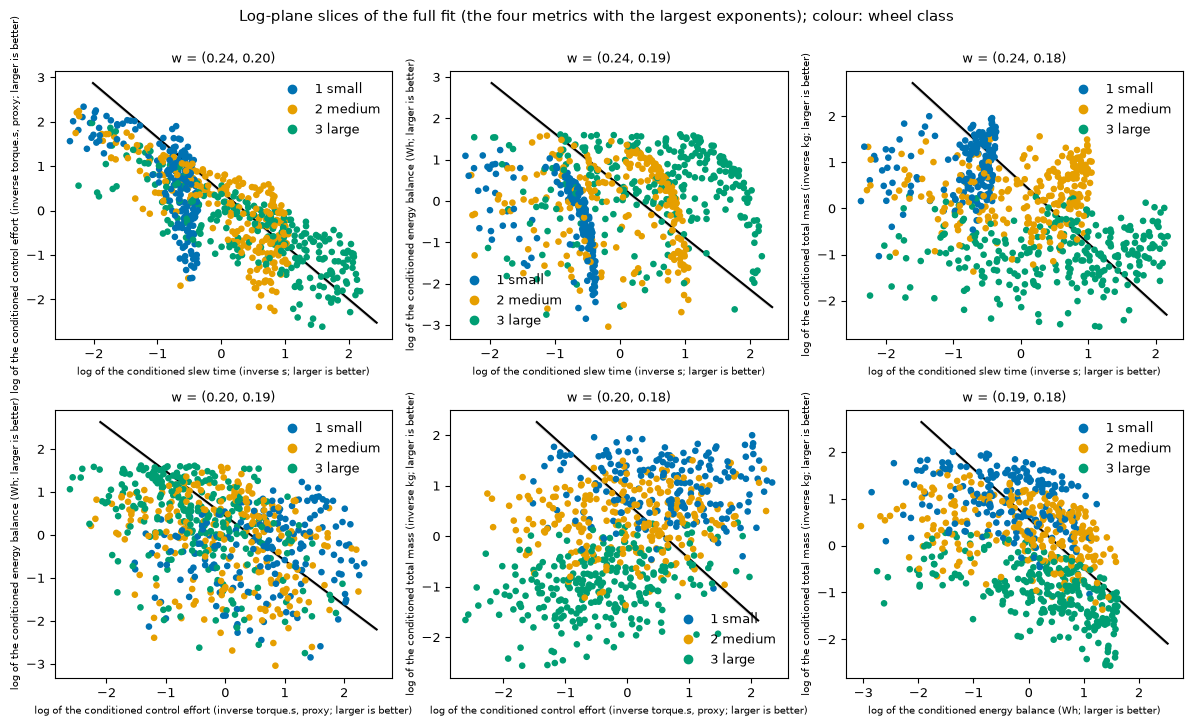

In [10]:
# CELL: log-planes
# A 2-D slice of the full ten-metric fit: the exponents of two metrics renormalised to sum to one, the offset
# adjusted for the other eight metrics held at their near-frontier median.
logv = est.score_samples(M)
near = np.abs(logv) < 1 / tau
U = np.log(M)
order = np.argsort(-est.exponents_[0])[:4]
pairs = [(order[i], order[j]) for i in range(4) for j in range(i + 1, 4)]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
for ax, (j, k) in zip(axes.ravel(), pairs, strict=True):
    w = est.exponents_[0]
    rest = [i for i in range(len(ATTRS)) if i not in (j, k)]
    beta = est.log_offset_[0] - w[rest] @ np.median(U[near][:, rest], axis=0)
    s = w[j] + w[k]
    shadow = HyperbolicTradeSpace(temperature=tau)
    shadow.exponents_ = np.array([[w[j] / s, w[k] / s]])
    shadow.log_offset_ = np.array([beta / s])
    wheel = feasible.wheel_class.map(WHEEL_LABEL).to_numpy()
    plot_log_plane(shadow, M[:, [j, k]], color=wheel, ax=ax)
    ax.set_xlabel("log of the " + cond_label(ATTRS[j]), fontsize=7)
    ax.set_ylabel("log of the " + cond_label(ATTRS[k]), fontsize=7)
    ax.set_title(f"w = ({w[j]:.2f}, {w[k]:.2f})", fontsize=9)
fig.suptitle(
    "Log-plane slices of the full fit (the four metrics with the largest exponents); colour: wheel class",
    y=1.0,
)
save(fig, "04_log_planes")

**What the figures show.** In both subset views a tenth of the designs lie on or beyond the surface (0.106 and 0.102), as the temperature selection intended. The edge-on views (right) show whether the surface hugs the upper envelope. In the first subset it does: the near-frontier designs, ringed in black, lie along the black line from its lower end to its upper end, the largest gap below it among them is 0.116 in log units (the half-width of the band in that view is 0.13), and the exponents are 0.45 on slew time, 0.04 on pointing error and 0.51 on control effort, so pointing error hardly binds in that three-metric view. In the second subset the surface hugs the cloud only over its lower and middle range, where the near-frontier designs sit on the line; towards the upper end the line runs well above every design, so the surface extends beyond the sampled designs there and the 3-D wireframe overstates what the data support. The slices (figure 04) show the surface as a line cutting a cloud; the wheel classes occupy different regions of the clouds, with large wheels towards the fast end of the slew-time axis and the low end of the oriented mass metric (the heavy designs). These are views of a ten-dimensional fit, not fits of two or three metrics.

*Next:* position along the frontier, and where the sample leaves space.


## 6 · Frontier coordinates, holes and white-space targets

The chart $[Z\mid\log V]$ splits each design into a position along the frontier, $Z$ (log-ratio coordinates, L8), and a distance from it, $\log V$. Designs far apart in $Z$ are different compromises; designs close in $Z$ are similar compromises. Hole finding supports at most three chart coordinates, so this section is a **subset view**: the model is refitted on four metrics, slew time, pointing error, control effort and total mass, which gives three coordinates. The energy attributes are not in this view.

`find_holes` marks grid cells inside the convex hull of the chart that lie far from every design. A hole is a candidate, not a verdict: it can be an opportunity, a stratum that hardware cannot occupy, or a region simply not sampled (`docs/limitations.md`). `frontier_targets` puts $V=1$ above a hole and maps it back to attributes (L8, L9).


four-metric subset view: slew time, pointing error, control effort, total mass; tau = 15.37, exponents [0.439 0.057 0.474 0.03 ]
chart coordinates Z: 3 (d - 1); near-frontier designs (|log V| < 1/tau): 71
holes found (grid 30^3, threshold 2.0 x median nearest-neighbour distance): 1965

white-space targets (V = 1 above the three most isolated, separated holes), in attribute units:
 hole score  slew time (s)  pointing error (deg)  control effort ((torque.s, proxy))  total mass (kg)
      4.834          5.733             0.0006828                              0.1427            13.05
      4.717          5.448              0.002712                              0.1337            12.65
      4.551           5.18              0.002116                               0.144            12.73


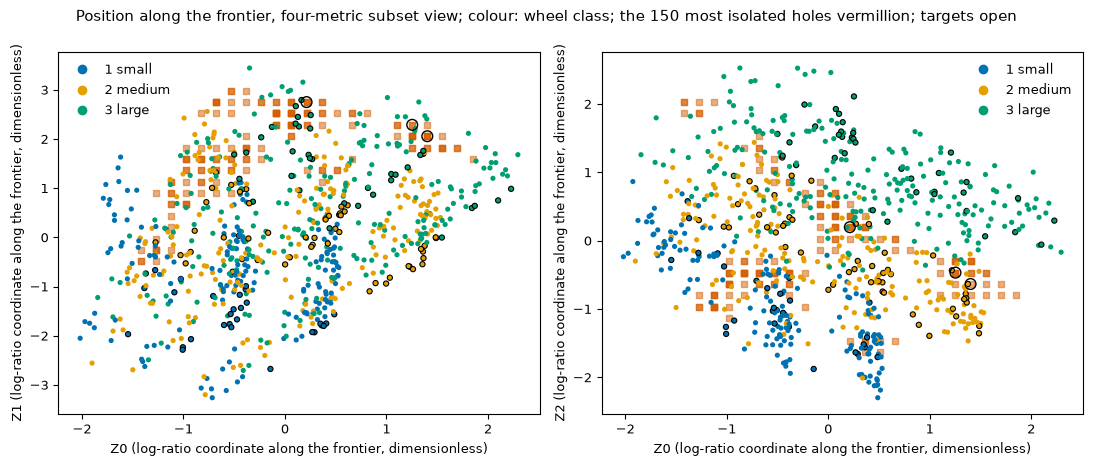

In [11]:
# CELL: holes
ATTR4 = ["slew_time_s", "pointing_error_deg", "control_effort", "total_mass_kg"]
c4, M4, tau4, est4 = subset_fit(feasible, ATTR4)
pre4 = c4.named_transformers_["metrics"]
chart4 = est4.transform(M4)
Z4, logv4 = chart4[:, :-1], chart4[:, -1]
holes, hscore = find_holes(Z4, resolution=30, threshold=2.0)
print(
    f"four-metric subset view: {', '.join(SHORT[a] for a in ATTR4)}; tau = {tau4:.2f}, exponents {np.round(est4.exponents_[0], 3)}"
)
print(
    f"chart coordinates Z: {Z4.shape[1]} (d - 1); near-frontier designs (|log V| < 1/tau): {int((np.abs(logv4) < 1 / tau4).sum())}"
)
print(f"holes found (grid 30^3, threshold 2.0 x median nearest-neighbour distance): {len(holes)}")

# three well-separated holes, most isolated first
tree_nn = np.sort(np.linalg.norm(Z4[:, None] - Z4[None], axis=2), axis=1)[:, 1]
sep = 1.5 * np.median(tree_nn)
pick = []
for h in holes:
    if all(np.linalg.norm(h - p) > sep for p in pick):
        pick.append(h)
    if len(pick) == 3:
        break
pick = np.array(pick)
tg = frontier_targets(pick, est4, pre4)
tab = pd.DataFrame(tg["attributes"], columns=[f"{SHORT[a]} ({UNITS[a]})" for a in ATTR4])
tab.insert(
    0, "hole score", hscore[[int(np.argmin(np.linalg.norm(holes - p, axis=1))) for p in pick]]
)
print(
    "\nwhite-space targets (V = 1 above the three most isolated, separated holes), in attribute units:"
)
print(tab.to_string(index=False))

wheel4 = feasible.wheel_class.map(WHEEL_LABEL).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, cols in zip(axes, [(0, 1), (0, 2)], strict=True):
    plot_frontier_coordinates(
        Z4[:, list(cols)],
        logv4,
        color=wheel4,
        holes=holes[:150][:, list(cols)],
        targets=pick[:, list(cols)],
        band=1 / tau4,
        ax=ax,
    )
    ax.set_xlabel(f"Z{cols[0]} (log-ratio coordinate along the frontier, dimensionless)")
    ax.set_ylabel(f"Z{cols[1]} (log-ratio coordinate along the frontier, dimensionless)")
fig.suptitle(
    "Position along the frontier, four-metric subset view; colour: wheel class; the 150 most isolated holes vermillion; targets open",
    y=1.0,
)
save(fig, "05_coordinates_holes")

**What the output shows.** At $\tau=15.4$ the four-metric fit has 71 near-frontier designs. The grid finds 1965 holes at the threshold of twice the median neighbour distance; the figure draws the 150 most isolated. The three well-separated targets ask for slew times of 5.2 to 5.7 s (the fastest sampled design takes 5.4 s), pointing errors of 0.0007 to 0.0027 deg, control effort of 0.13 to 0.14 and total mass of 12.7 to 13.1 kg. Whether such designs can be built from the hardware strata sampled here is not something the figure can say; section 13 simulates three proposals aimed at white space and reports what happened.

*Next:* the question the notebook was built to answer, asked of the full fit.


## 7 · The tension report

`tension_report` reads three things from a fitted trade space and states them without interpretation. (1) **The contending set**: the metrics with positive exponent at $\tau=\infty$, read from the support of a linear program, of any size and with no prior choice of which or how many. (2) **Association** among the near-frontier designs ($|\log V|<1/\tau$): the correlation of the log-metrics, negative where metrics are traded and positive where they move together; Pearson is shown with Spearman in brackets as a check. (3) **Principal directions** of the near-frontier chart coordinates, with their loadings on the metrics.

The report states its own caution, the closure effect: near the frontier $w\cdot u$ is nearly constant, so a binding constraint induces negative association among the participating metrics even where no designer traded them (printed below). Negative association is evidence of a tension only together with the exponents and the directions.

The report is run on the full ten-attribute fit and, for comparison, on the four-metric subset of section 6. The wheel-class counts of the near-frontier designs are printed with it. Nothing about the result is stated in this notebook before the output below.


In [12]:
# CELL: tension-report-primary
def describe(rep, names, label):
    print(f"TENSION REPORT: {label}")
    print(
        f"n_lemma = {rep.n_lemma} ({rep.lemma_name}); near-frontier designs {rep.n_near_frontier} "
        f"(band 1/tau = {rep.band:.4f})"
    )
    cs = ", ".join(
        f"{names[j]} {w:.3f}"
        for j, w in sorted(
            zip(rep.contending_set, rep.contending_exponents, strict=True), key=lambda t: -t[1]
        )
    )
    print(f"contending set at tau = inf: {cs}")
    wk = ", ".join(
        f"{names[j]} {w:.3f}"
        for j, w in sorted(enumerate(rep.exponents), key=lambda t: -t[1])
        if w > 1e-3
    )
    print(f"working-tau exponents (above 1e-3): {wk}")


names10 = [SHORT[a] for a in ATTRS]
rep = tension_report(est, M)
describe(rep, names10, "full fit, ten attributes")
near = np.abs(est.score_samples(M)) < rep.band
cls = feasible.wheel_class.to_numpy()
print(
    "near-frontier designs by wheel class: "
    + ", ".join(f"{w} {int((near & (cls == w)).sum())}" for w in WHEELS)
    + "; by tracker grade: "
    + ", ".join(f"{t} {int((near & (feasible.st_grade.to_numpy() == t)).sum())}" for t in TRACKERS)
)

rep_s = tension_report(est, M, association="spearman")
A, As = rep.association, rep_s.association
pairs_of_interest = [
    ("settling time", "slew time"),
    ("power margin", "energy balance"),
    ("eclipse reserve", "depth of discharge"),
    ("settling time", "total mass"),
    ("slew time", "total mass"),
    ("pointing error", "control effort"),
    ("settling time", "pointing error"),
    ("slew time", "control effort"),
    ("settling time", "control effort"),
    ("pointing error", "total mass"),
    ("total mass", "peak slew power"),
    ("total mass", "control effort"),
    ("settling time", "peak slew power"),
    ("slew time", "peak slew power"),
    ("pointing error", "peak slew power"),
]
print(
    f"\nassociation among the {rep.n_near_frontier} near-frontier designs (Pearson of log-metrics; Spearman in brackets)"
)
for a, b in pairs_of_interest:
    i, j = names10.index(a), names10.index(b)
    print(f"  {a:>16s} , {b:<18s} {A[i, j]:+.2f}  ({As[i, j]:+.2f})")
print(
    "\nprincipal tension directions (share of near-frontier spread; five largest loadings on the oriented log-metrics)"
)
for r in range(4):
    ld = rep.tension_loadings[r]
    top = np.argsort(-np.abs(ld))[:5]
    print(
        f"  direction {r + 1} ({rep.explained_spread[r]:.3f}): "
        + ", ".join(f"{names10[j]} {ld[j]:+.2f}" for j in top)
    )
print("\nclosure note:", rep.closure_note)

TENSION REPORT: full fit, ten attributes
n_lemma = 6 (6-lemma); near-frontier designs 51 (band 1/tau = 0.0262)
contending set at tau = inf: total mass 0.223, slew time 0.201, energy balance 0.169, control effort 0.143, pointing error 0.135, depth of discharge 0.129
working-tau exponents (above 1e-3): slew time 0.240, control effort 0.197, energy balance 0.190, total mass 0.180, pointing error 0.102, depth of discharge 0.091
near-frontier designs by wheel class: small 20, medium 25, large 6; by tracker grade: coarse 15, medium 17, fine 19

association among the 51 near-frontier designs (Pearson of log-metrics; Spearman in brackets)
     settling time , slew time          +0.91  (+0.88)
      power margin , energy balance     +0.98  (+0.97)
   eclipse reserve , depth of discharge +0.98  (+1.00)
     settling time , total mass         -0.54  (-0.34)
         slew time , total mass         -0.48  (-0.33)
    pointing error , control effort     -0.36  (-0.48)
     settling time , pointing e

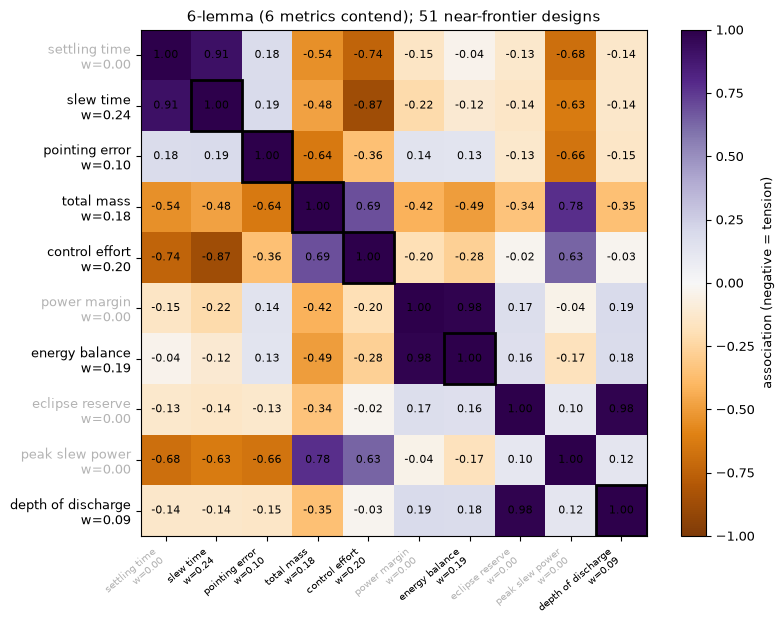

In [13]:
# CELL: tension-figure
fig, ax = plt.subplots(figsize=(8.2, 6.4))
plot_tensions(rep, names=names10, ax=ax)
ax.set_title(ax.get_title() + f"; {rep.n_near_frontier} near-frontier designs")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=7)
save(fig, "06_tension_association")

In [14]:
# CELL: tension-report-subset
names4 = [SHORT[a] for a in ATTR4]
rep4 = tension_report(est4, M4)
describe(
    rep4, names4, "four-metric subset view (slew time, pointing error, control effort, total mass)"
)
near4 = np.abs(est4.score_samples(M4)) < rep4.band
print(
    "near-frontier designs by wheel class: "
    + ", ".join(f"{w} {int((near4 & (cls == w)).sum())}" for w in WHEELS)
)
A4, A4s = rep4.association, tension_report(est4, M4, association="spearman").association
for a, b in [
    ("slew time", "total mass"),
    ("pointing error", "control effort"),
    ("slew time", "control effort"),
    ("pointing error", "total mass"),
    ("slew time", "pointing error"),
    ("control effort", "total mass"),
]:
    i, j = names4.index(a), names4.index(b)
    print(f"  {a:>16s} , {b:<16s} {A4[i, j]:+.2f}  ({A4s[i, j]:+.2f})")
for r in range(3):
    ld = rep4.tension_loadings[r]
    print(
        f"  direction {r + 1} ({rep4.explained_spread[r]:.3f}): "
        + ", ".join(f"{names4[j]} {ld[j]:+.2f}" for j in np.argsort(-np.abs(ld)))
    )

TENSION REPORT: four-metric subset view (slew time, pointing error, control effort, total mass)
n_lemma = 4 (4-lemma); near-frontier designs 71 (band 1/tau = 0.0651)
contending set at tau = inf: control effort 0.469, slew time 0.431, pointing error 0.072, total mass 0.027
working-tau exponents (above 1e-3): control effort 0.474, slew time 0.439, pointing error 0.057, total mass 0.030
near-frontier designs by wheel class: small 21, medium 28, large 22
         slew time , total mass       -0.76  (-0.76)
    pointing error , control effort   -0.42  (-0.50)
         slew time , control effort   -0.99  (-0.99)
    pointing error , total mass       -0.63  (-0.66)
         slew time , pointing error   +0.32  (+0.41)
    control effort , total mass       +0.78  (+0.79)
  direction 1 (0.770): slew time +0.57, total mass -0.52, control effort -0.47, pointing error +0.43
  direction 2 (0.197): pointing error -0.70, slew time +0.62, total mass +0.30, control effort -0.22
  direction 3 (0.032): co

**What the report printed (a reading of the output, not yet an explanation).**

*Full fit.* The contending set at $\tau=\infty$ has six members, a 6-lemma: total mass 0.223, slew time 0.201, energy balance 0.169, control effort 0.143, pointing error 0.135 and depth of discharge 0.129. It is not a set anyone chose; settling time, power margin, eclipse reserve and peak slew power are outside it. There are 51 near-frontier designs: 20 with small wheels, 25 with medium and 6 with large. Among them:

- negative association (traded): slew time with control effort $-0.87$, settling time with control effort $-0.74$, pointing error with total mass $-0.64$, settling time with total mass $-0.54$ (Spearman $-0.34$), slew time with total mass $-0.48$ (Spearman $-0.33$), pointing error with control effort $-0.36$ (Spearman $-0.48$);
- positive association (aligned): settling time with slew time $+0.91$, power margin with energy balance $+0.98$, eclipse reserve with depth of discharge $+0.98$, total mass with peak slew power $+0.78$, total mass with control effort $+0.69$; settling time with pointing error is only $+0.18$. Peak slew power, which has no exponent, is traded against settling time ($-0.68$), slew time ($-0.63$) and pointing error ($-0.66$).
- principal directions: the first (46 % of the near-frontier spread) loads pointing error $+0.43$ and slew time $+0.40$ against total mass $-0.42$, peak slew power $-0.41$ and control effort $-0.40$; the second (21 %) loads depth of discharge $-0.52$ and eclipse reserve $-0.37$ against total mass $+0.46$ and slew time $+0.39$.

*Four-metric subset.* The contending set has four members (control effort 0.469, slew time 0.431, pointing error 0.072, total mass 0.027), 71 near-frontier designs (21 / 28 / 22 by wheel class) and a first direction carrying 77 % of the spread. Slew time is associated with control effort at $-0.99$ and with total mass at $-0.76$; pointing error with control effort at $-0.42$ and with total mass at $-0.63$.

Two cautions that the output itself carries. The associations rest on 51 near-frontier designs, of which only 6 have large wheels. The weakest of the negative associations, pointing error with control effort at $-0.36$, is only just beyond a threshold of $-0.30$ and settling time with pointing error at $+0.18$ is close to zero; these are thin margins and are disclosed again in section 15.

*Next:* does this reading survive a different conditioning of the same data?

## 8 · Does it persist? Sensitivity to the conditioning

Conditioning defines the question, so the report is rerun under changes to it. Five variants: the baseline (standard scaler); the robust scaler (unit log-interquartile range instead of unit standard deviation); the reference shifted by $+0.5$ log-spread on all ten metrics; the reference shifted by $+0.5$ and $-0.5$ alternately over the ten metrics; and a refit on eight metrics, dropping slew time and energy balance (one of each of two near-redundant pairs). For each, $\tau$ is selected afresh at the same target. A uniform shift of the reference, the same constant on all ten metrics, adds that constant to every score $w\cdot u$ and to the fitted offset $\beta$ and, by L2, leaves the exponents unchanged (it does not multiply the scores); it is included as a check on the code, not as a probe. The alternating shift is the real probe of the reference point.


In [15]:
# CELL: sensitivity
def summarise(label, Mv, names, scaler_note=""):
    t, e = fit_space(Mv)
    r = tension_report(e, Mv)
    cs = ", ".join(
        names[j]
        for j in sorted(
            r.contending_set, key=lambda j: -r.contending_exponents[list(r.contending_set).index(j)]
        )
    )
    top = int(np.argmax(r.exponents))
    ld = r.tension_loadings[0]
    d1 = ", ".join(f"{names[j]} {ld[j]:+.2f}" for j in np.argsort(-np.abs(ld))[:4])
    eff = ld[names.index("control effort")]
    ag = ", ".join(
        f"{n} {ld[names.index(n)]:+.2f}" for n in ("slew time", "settling time") if n in names
    )
    return {
        "variant": label,
        "tau": t,
        "n_lemma": r.n_lemma,
        "mass in contending set": "total mass" in cs,
        "contending set (largest first)": cs,
        "largest working exponent": f"{names[top]} {r.exponents[top]:.2f}",
        "direction 1 (top loadings)": d1,
        "dir 1: effort": f"{eff:+.2f}",
        "dir 1: agility metrics present": ag,
    }


rows = [summarise("standardize (the baseline of this notebook)", M, names10)]
c_rob = make_conditioner(ATTRS, scaler="robust")
M_rob = c_rob.fit_transform(feasible)[[f"metrics__{a}" for a in ATTRS]].to_numpy()
rows.append(summarise("robust scaler (unit log-IQR)", M_rob, names10))
rows.append(
    summarise("reference shifted +0.5 log-spread on all ten metrics", M * np.exp(0.5), names10)
)
alt = np.where(np.arange(10) % 2 == 0, 0.5, -0.5)
rows.append(
    summarise(
        "reference shifted +0.5 / -0.5 alternately over the ten metrics", M * np.exp(alt), names10
    )
)
keep = [a for a in ATTRS if a not in ("slew_time_s", "energy_balance_wh")]
c8 = make_conditioner(keep)
M8 = c8.fit_transform(feasible)[[f"metrics__{a}" for a in keep]].to_numpy()
rows.append(
    summarise("eight metrics (slew time and energy balance dropped)", M8, [SHORT[a] for a in keep])
)
sens = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    print(
        sens.drop(columns=["dir 1: effort", "dir 1: agility metrics present"]).to_string(
            index=False
        )
    )
print(
    "\nfirst principal direction: loading of control effort and of the agility metrics present in the variant"
)
with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    print(
        sens[["variant", "dir 1: effort", "dir 1: agility metrics present"]].to_string(index=False)
    )

                                                       variant   tau  n_lemma  mass in contending set                                                              contending set (largest first) largest working exponent                                                              direction 1 (top loadings)
                   standardize (the baseline of this notebook)  38.1        6                    True   total mass, slew time, energy balance, control effort, pointing error, depth of discharge           slew time 0.24     pointing error +0.43, total mass -0.42, peak slew power -0.41, control effort -0.40
                                  robust scaler (unit log-IQR) 54.77        6                    True peak slew power, total mass, pointing error, eclipse reserve, energy balance, settling time          total mass 0.29           control effort -0.62, total mass -0.49, pointing error +0.37, slew time +0.35
          reference shifted +0.5 log-spread on all ten metrics  38.1        6  

**What the output shows.** Total mass stays in the contending set in all five variants, and so does pointing error. An agility metric stays in all five, but which one changes: slew time in three variants and settling time in the other two (robust scaler and the eight-metric refit, where slew time is removed or displaced); the two are near-redundant (section 9). Control effort is in the contending set in three variants and leaves it under the robust scaler and in the eight-metric refit; it remains among the largest loadings of the first principal direction in all five. The size of the contending set is 6 in four variants and 5 in the eight-metric refit. The largest working-temperature exponent is slew time in two variants and total mass in three. The shift on all ten metrics reproduces the baseline exactly, as L2 requires.

**Persistence, stated with its exception.** The detail of the contending set is not stable (which member of an aligned pair enters, whether effort is a member). What persists is that total mass, an agility metric and pointing error contend. Control effort loads against an agility metric in the first principal direction in four of the five variants (baseline, robust scaler, alternating shift, and the all-metric shift, which is the baseline again by L2, so three independent variants). The exception is the eight-metric refit: its first direction is led by total mass ($-0.58$) and control effort ($-0.46$), and settling time loads only $+0.04$, so no agility metric loads against effort there (second table above).

## 9 · Interpretation: why the report looks the way it does

*Everything in this section is the author's interpretation, offered for human validation. The output above is what the model computed; what follows is an explanation of it, and it can be wrong. Each item gives what the output showed, the mechanism that could produce it, the design variable through which it acts and what would change it. First, a few facts read from the data that the explanations lean on.*


In [16]:
# CELL: evidence
# Facts used by the interpretation below; each is read from the data, none is a model output.
g = (
    feasible.groupby("wheel_class")
    .agg(
        n=("slew_time_s", "size"),
        slew_time_s=("slew_time_s", "median"),
        settling_time_s=("settling_time_s", "median"),
        control_effort=("control_effort", "median"),
        pointing_error_deg=("pointing_error_deg", "median"),
        total_mass_kg=("total_mass_kg", "median"),
        adcs_mass_kg=("adcs_mass_kg", "median"),
        peak_slew_power_w=("peak_slew_power_w", "median"),
    )
    .loc[WHEELS]
)
print("medians by wheel class (feasible designs):")
print(g.to_string())
g2 = (
    feasible.groupby("st_grade")
    .agg(
        n=("slew_time_s", "size"),
        pointing_error_deg=("pointing_error_deg", "median"),
        total_mass_kg=("total_mass_kg", "median"),
        adcs_mass_kg=("adcs_mass_kg", "median"),
    )
    .loc[TRACKERS]
)
print("\nmedians by star-tracker grade:")
print(g2.to_string())
cfgs = ["Kp", "Kd", "panel_span_m", "battery_wh"]
cc = feasible[cfgs + ATTRS].corr(method="spearman").loc[cfgs, ATTRS]
cc.columns = [SHORT[a] for a in ATTRS]
print(
    "\nSpearman correlation of the configuration variables with the raw attributes (all feasible designs):"
)
print(cc.round(2).T.to_string())
i_mass = names10.index("total mass")
print(
    "\nassociation of total mass with the other metrics among the near-frontier designs (Pearson of oriented log-metrics):"
)
print(
    ", ".join(f"{names10[j]} {rep.association[i_mass, j]:+.2f}" for j in range(10) if j != i_mass)
)
print(
    f"\nmedian slew time / settling time on the feasible set: {np.median(feasible.slew_time_s / feasible.settling_time_s):.2f} (primary)"
)

medians by wheel class (feasible designs):
               n  slew_time_s  settling_time_s  control_effort  pointing_error_deg  total_mass_kg  adcs_mass_kg  peak_slew_power_w
wheel_class                                                                                                                       
small        191        32.99            104.2         0.02922             0.00313          12.65          0.81              1.804
medium       248        18.34            41.45         0.04537            0.002892          13.31           1.2                  2
large        267        13.82            21.48         0.07206            0.002918          14.46          2.25                6.8

medians by star-tracker grade:
            n  pointing_error_deg  total_mass_kg  adcs_mass_kg
st_grade                                                      
coarse    253            0.008366          13.15             1
medium    241            0.002897          13.41           1.2
fine      212     

**Slew time and settling time against control effort** (association $-0.87$ and $-0.74$; effort and slew time both in the contending set). *Mechanism:* a rest-to-rest slew with a torque-limited wheel is faster the larger the torque and peak rate it develops, and the control effort (the time integral of the commanded torque, a proxy for what the wheel and the bus pay) grows with the torque applied and the rate reached.

*Slew time and settling time against control effort: design variable.* the gains. Across the feasible designs Kp is correlated with effort at $+0.69$ and with slew time at $-0.62$, and Kd at $-0.51$ and $+0.50$ (Spearman): a stiffer loop is faster and costs more effort, more damping is slower and spares effort. The wheel class acts too: the large wheel's median slew time is 13.8 s against 33.0 s for the small, and its median effort 0.072 against 0.029.

*Slew time and settling time against control effort: what would change it.* a lower slew-axis inertia (smaller panel span) shortens the slew at the same torque; a different definition of effort (energy rather than torque-time) would change the metric; a loop whose slow pole sets the arrival time, as in the baseline regime, makes the effort cost of speed even steeper (association $-0.96$, section 14). Because two strongly participating metrics near a frontier are forced into negative association by the closure effect, the association is not the evidence; the exponents are, and both metrics have large exponents in the contending set.

**Total mass against slew time and settling time** (association $-0.48$ and $-0.54$, Spearman $-0.33$ and $-0.34$; total mass has the largest exponent in the contending set). *Mechanism:* in the aggressive-gain regime the proportional demand exceeds every wheel's torque cap from the first instant, so the wheel is the bottleneck and its class sets the speed (this is the regime the dataset was built to create; the case-enrichment record is in `docs/superpowers/notes/adcs-tensions-probe.md`). A larger wheel is faster, and it is the largest single mass lever: the median ADCS mass is 0.81 kg for small-wheel designs and 2.25 kg for large-wheel designs, and total mass 12.7 kg against 14.5 kg.

*Total mass against slew time and settling time: design variable.* wheel class (panel span adds mass too: Spearman $+0.51$ with total mass).

*Total mass against slew time and settling time: what would change it.* the regime. In the stock-gain baseline the association is only $-0.12$ and $-0.10$ and mass is not in the contending set (section 14). Within the primary regime, a lighter wheel of the same torque would loosen the trade. Two qualifications read from the output: the Spearman values are only just beyond $-0.30$, and only 6 of the 51 near-frontier designs have large wheels, whose median $\log V$ is $-0.26$ against $-0.15$ and $-0.12$ for small and medium and of which 2.2 % lie near the frontier (about 10 % for the others). The heavy end of the trade is thinly represented; the association is carried mostly by small and medium wheels.

**Pointing error against control effort** (association $-0.36$, Spearman $-0.48$; both in the contending set). *Mechanism:* pointing error combines the steady-state error under a constant disturbance torque, which falls as the proportional gain rises, with the star-tracker's accuracy floor. Pointing error and Kp are correlated at $-0.28$ (higher Kp, smaller error), and higher Kp costs effort.

*Pointing error against control effort: design variable.* Kp, and the tracker grade through the floor.

*Pointing error against control effort: what would change it.* a smaller disturbance torque, or a finer tracker, lifts the floor and removes the gain's role. This margin is thin ($-0.36$ against the $-0.30$ threshold, with 51 designs); in the baseline regime it is $-0.70$.

**Pointing error against total mass** (association $-0.64$; both in the contending set). *Mechanism:* the star-tracker grade. The fine tracker's median pointing error is 0.0010 deg against 0.0084 deg for the coarse, and it is the heavier part (ADCS mass 1.75 kg against 1.00 kg; total mass 14.0 against 13.2 kg at the median).

*Pointing error against total mass: design variable.* tracker grade.

*Pointing error against total mass: what would change it.* a lighter fine sensor. In the baseline regime the association is $-0.34$.

**The energy attributes against total mass** (energy balance and depth of discharge are in the contending set, with associations to total mass of $-0.49$ and $-0.35$; the second principal direction is mainly depth of discharge and eclipse reserve against mass). *Mechanism:* energy is bought with panel area and battery capacity, and both add mass. Panel span is correlated with total mass at $+0.51$ and battery capacity at $+0.36$.

*The energy attributes against total mass: design variable.* panel span (which sets the power margin and energy balance almost completely: Spearman $0.98$ and $1.00$) and battery capacity (which sets the eclipse reserve and depth of discharge: $1.00$ and $-1.00$).

*The energy attributes against total mass: what would change it.* lighter panels or cells.

**Aligned pairs that are accounting identities, not findings.** Settling time with slew time ($+0.91$): both measure the same slow-pole tail of the PD loop; the median slew time is 0.60 of the settling time in this regime and 0.74 in the baseline (section 14). Power margin with energy balance ($+0.98$): both are set by panel span. Eclipse reserve with depth of discharge ($+0.98$): both are set by battery capacity. Which member of such a pair enters the contending set (energy balance rather than power margin, depth of discharge rather than eclipse reserve) is a matter of the linear program, not a finding; the sensitivity check confirms it, since the eight-metric refit lets power margin and settling time enter in their place. Settling time with pointing error is $+0.18$, near zero here (and $+0.69$ in the baseline): both improve with Kp, but not strongly enough to call them aligned in this regime.

**Associations the output exposes and this notebook does not explain.** Peak slew power carries no exponent yet is associated with settling time ($-0.68$), slew time ($-0.63$) and pointing error ($-0.66$); it is a metric that moves with the wheel (below) and is not in the contending set, so this is read as a by-product of wheel class and not as a separate tension. Total mass with peak slew power ($+0.78$) and with control effort ($+0.69$) are positive: among the near-frontier designs the heavier ones also draw more peak power and spend more effort, and the large wheel has a median peak slew power of 6.8 W against 1.8 W (small) and 2.0 W (medium). A wheel class bundles mass, power and effort, which is a hypothesis consistent with the data; it is not established here.

**Wheel class.** Wheel class is both a feasibility boundary and a frontier tension when the wheel is the bottleneck: the momentum limit removes 37.2 % of small-wheel and 17.4 % of medium-wheel designs, and, once feasible, wheel class sets slew speed against mass. It is a feasibility boundary only in the baseline regime (section 14).

**What the report does not expose.** No tension involving power as a limit on the slew: power never limits a slew in this dataset (section 15). Settling time, power margin, eclipse reserve and peak slew power have no exponent at the working temperature.

*Next:* the same fit applied as a tool to the individual designs and the categories.


## 10 · V by category and per-category refits

$\log V$ of each design against each configuration variable shows where on the frontier the sampled hardware sits; the grey strip is the band $1/\tau$ and points on or above the black line lie on or beyond the fitted surface. The continuous variables are grouped into thirds in the table. Then the full ten-attribute model is refitted separately inside each wheel class (conditioning, temperature and report each from scratch) and the contending sets are compared.


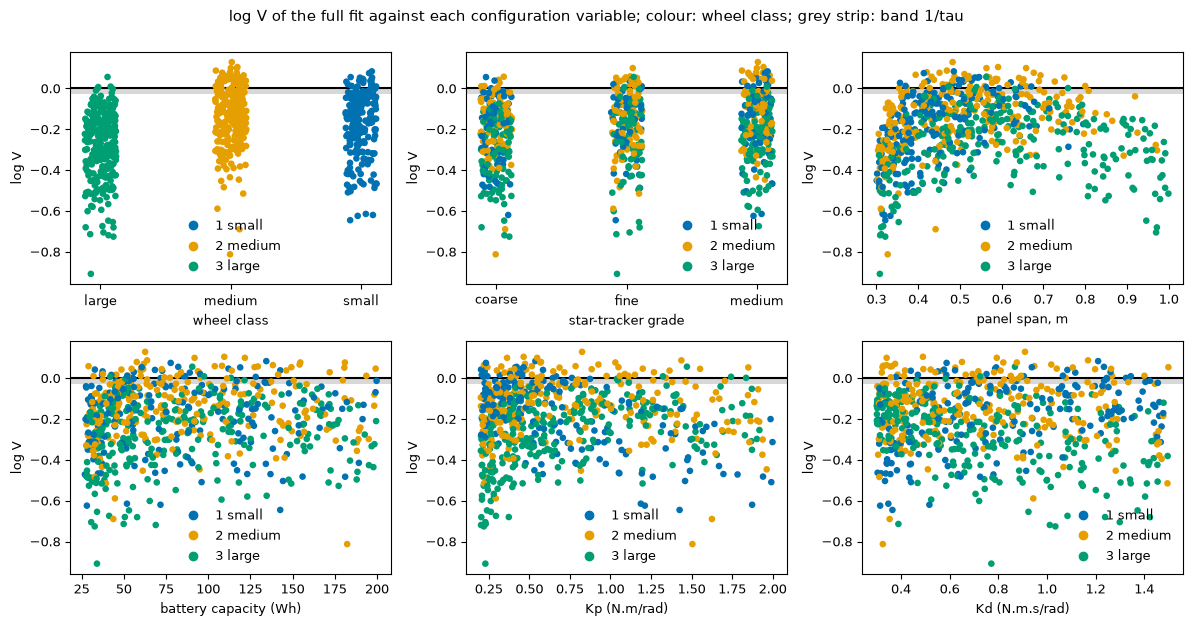

    variable        level   n  median log V  share near frontier  share log V >= 0
 wheel_class        small 191       -0.1517               0.1047            0.1152
 wheel_class       medium 248       -0.1211               0.1008            0.1694
 wheel_class        large 267       -0.2592              0.02247           0.01498
    st_grade       coarse 253       -0.2108              0.05929           0.03557
    st_grade       medium 241       -0.1822              0.07054            0.1369
    st_grade         fine 212       -0.1512              0.08962            0.1226
panel_span_m    low third 236       -0.2602              0.03814           0.04237
panel_span_m middle third 235       -0.1222               0.1234            0.1574
panel_span_m   high third 235        -0.171              0.05532           0.08936
  battery_wh    low third 236       -0.2142              0.07203           0.04661
  battery_wh middle third 235       -0.1569               0.0766            0.1404
  ba

In [17]:
# CELL: v-by-category
logv_full = est.score_samples(M)
band = 1 / tau
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
variables = [
    ("wheel_class", "wheel class"),
    ("st_grade", "star-tracker grade"),
    ("panel_span_m", "panel span, m"),
    ("battery_wh", "battery capacity (Wh)"),
    ("Kp", "Kp (N.m/rad)"),
    ("Kd", "Kd (N.m.s/rad)"),
]
for ax, (v, lab) in zip(axes.ravel(), variables, strict=True):
    plot_v_by_variable(feasible[v].to_numpy(), logv_full, color=wheel4, band=band, ax=ax, label=lab)
fig.suptitle(
    "log V of the full fit against each configuration variable; colour: wheel class; grey strip: band 1/tau",
    y=1.0,
)
save(fig, "07_v_by_category")
summ = []
for v in ["wheel_class", "st_grade"]:
    for lev in WHEELS if v == "wheel_class" else TRACKERS:
        sel = (feasible[v] == lev).to_numpy()
        summ.append(
            {
                "variable": v,
                "level": lev,
                "n": int(sel.sum()),
                "median log V": np.median(logv_full[sel]),
                "share near frontier": np.mean(np.abs(logv_full[sel]) < band),
                "share log V >= 0": np.mean(logv_full[sel] >= 0),
            }
        )
for v in ["panel_span_m", "battery_wh", "Kp", "Kd"]:
    q = pd.qcut(feasible[v], 3, labels=["low third", "middle third", "high third"])
    for lev in q.cat.categories:
        sel = (q == lev).to_numpy()
        summ.append(
            {
                "variable": v,
                "level": lev,
                "n": int(sel.sum()),
                "median log V": np.median(logv_full[sel]),
                "share near frontier": np.mean(np.abs(logv_full[sel]) < band),
                "share log V >= 0": np.mean(logv_full[sel] >= 0),
            }
        )
print(pd.DataFrame(summ).to_string(index=False))

In [18]:
# CELL: per-category-refits
rows = []
for lev in WHEELS:
    sel = (feasible.wheel_class == lev).to_numpy()
    sub = feasible[sel].reset_index(drop=True)
    c_l = make_conditioner(ATTRS)
    M_l = c_l.fit_transform(sub)[[f"metrics__{a}" for a in ATTRS]].to_numpy()
    try:
        t_l, e_l = fit_space(M_l)
        r_l = tension_report(e_l, M_l, min_near_frontier=5)
        cs = ", ".join(
            names10[j]
            for j in sorted(
                r_l.contending_set,
                key=lambda j: -r_l.contending_exponents[list(r_l.contending_set).index(j)],
            )
        )
        rows.append(
            {
                "wheel class": lev,
                "n": len(sub),
                "tau": t_l,
                "n_lemma": r_l.n_lemma,
                "near-frontier": r_l.n_near_frontier,
                "contending set (largest first)": cs,
            }
        )
    except ValueError as err:
        rows.append(
            {
                "wheel class": lev,
                "n": len(sub),
                "tau": np.nan,
                "n_lemma": np.nan,
                "near-frontier": np.nan,
                "contending set (largest first)": f"not reported: {str(err)[:60]}",
            }
        )
with pd.option_context("display.max_colwidth", 110, "display.width", 250):
    print(pd.DataFrame(rows).to_string(index=False))
print(
    "\nfull-sample contending set for comparison: "
    + ", ".join(
        names10[j]
        for j in sorted(
            rep.contending_set,
            key=lambda j: -rep.contending_exponents[list(rep.contending_set).index(j)],
        )
    )
)

wheel class   n   tau  n_lemma  near-frontier                                                                           contending set (largest first)
      small 191 336.5        6             12            pointing error, total mass, peak slew power, depth of discharge, power margin, control effort
     medium 248 135.8        7             19 pointing error, peak slew power, total mass, depth of discharge, power margin, control effort, slew time
      large 267 113.2        7             17 power margin, total mass, pointing error, depth of discharge, control effort, peak slew power, slew time

full-sample contending set for comparison: total mass, slew time, energy balance, control effort, pointing error, depth of discharge


**What the output shows.** Large wheels sit furthest from the frontier (median $\log V=-0.26$, 2.2 % near the band) against small ($-0.15$, 10.5 %) and medium ($-0.12$, 10.1 %). The middle thirds of panel span, battery capacity and Kp are nearest the frontier; the tracker grade moves the median $\log V$ little (coarse $-0.21$, medium $-0.18$, fine $-0.15$). Refitting within a wheel class, the temperatures selected are 336, 136 and 113 and the near-frontier samples are 12, 19 and 17 designs, so these refits are small samples. The contending sets differ from the pooled one and from each other: total mass, pointing error, control effort, peak slew power, depth of discharge and power margin appear in all three classes; slew time is absent for small wheels (6-lemma) and present for medium and large (7-lemma each). A reading, offered as the author's: within a class the wheel cannot vary, so the weight moves to the other levers, and slew time contends only where wheels can make a slew fast. With 12 to 19 near-frontier designs this reading is weak.

*Next:* individual designs.


## 11 · Candidates scored

Three hand-written candidate designs were chosen to span the trade space, without looking at any score (the precise design first used a medium wheel, failed the momentum flag and was changed to a large wheel before the final simulation; the candidates carry no predictions, so this does not touch the order of section 13): a fast, effort-hungry design (large wheel, medium tracker, aggressive gains); a precise design with a heavy sensor (large wheel, fine tracker); and a light, slow design (small wheel, coarse tracker, low gains). They were simulated once and cached with the three proposals of section 13. Each is scored by the full ten-attribute fit: $\log V$, novelty $V-1$ (the uniform factor by which a frontier design must improve to reach the design; L1), calibrated novelty (the rank of $\log V$ among the training designs, and $\tau\log V$), and the improvement factors (L7). Novelty is not preference: it measures distance from the learned surface, not desirability.


In [19]:
# CELL: candidates
checks = pd.read_csv(DATA / "check_designs_cubesat.csv")
preds = pd.read_csv(DATA / "check_predictions_cubesat.csv")
print(
    "read from data/check_designs_cubesat.csv and data/check_predictions_cubesat.csv (cached; the six designs were"
)
print("simulated once by examples/adcs/make_check_designs.py; nothing is simulated here)")
print(f"{len(checks)} rows; roles: {checks.role.value_counts().to_dict()}")
cand = checks[checks.role == "candidate"].reset_index(drop=True)
Mc = np.asarray(pre.transform(cand[ATTRS]))
nov = est.novelty_score(Mc)
cal = est.novelty_score(Mc, calibrated=True)
imp = est.improvement_factors(Mc)
t = pd.DataFrame(
    {
        "candidate": cand.name,
        "wheel": cand.wheel_class,
        "tracker": cand.st_grade,
        "log V": est.score_samples(Mc),
        "novelty V-1": nov,
        "rank among training": cal[:, 0],
        "tau*log V": cal[:, 1],
    }
)
print(t.to_string(index=False))
print(
    "\nimprovement factors V^(-1/w_j) (the factor on one metric alone that lands on V = 1; inf where w_j = 0):"
)
f = pd.DataFrame(imp, columns=names10, index=cand.name)
print(f.loc[:, est.exponents_[0] > 1e-3].to_string())
print("\nmeasured attributes:")
print(cand[["name", *ATTRS]].rename(columns=SHORT).to_string(index=False))

read from data/check_designs_cubesat.csv and data/check_predictions_cubesat.csv (cached; the six designs were
simulated once by examples/adcs/make_check_designs.py; nothing is simulated here)
6 rows; roles: {'candidate': 3, 'proposal': 3}
           candidate wheel tracker    log V  novelty V-1  rank among training  tau*log V
  fast_effort_hungry large  medium   -0.115      -0.1086               0.6686     -4.381
precise_heavy_sensor large    fine -0.07174     -0.06923                0.772     -2.733
          light_slow small  coarse  -0.1436      -0.1338               0.5949     -5.471

improvement factors V^(-1/w_j) (the factor on one metric alone that lands on V = 1; inf where w_j = 0):
                      slew time  pointing error  total mass  control effort  energy balance  depth of discharge
name                                                                                                           
fast_effort_hungry        1.616            3.08       1.897           1.791 

**What the output shows.** All three candidates lie inside the fitted frontier ($\log V$ of $-0.115$, $-0.072$ and $-0.144$; novelty $V-1$ of $-0.109$, $-0.069$ and $-0.134$), so none is beyond it. Their rank among the training $\log V$ values is 0.67, 0.77 and 0.59: each is better than more than half of the sampled designs. The precise design with the fine tracker is the closest to the frontier. The factor by which slew time alone would have to improve to reach $V=1$ is 1.62 (fast, effort-hungry), 1.35 (precise) and 1.82 (light, slow); the factors for total mass are 1.90, 1.49 and 2.23. Improving one metric alone to the frontier is not a design proposal, since the metrics are coupled through the configuration.


## 12 · The frontier in attribute units

Because the conditioning is log-affine and invertible (A4), the fitted frontier can be written as a monomial in the raw attributes (L9): $\log V=c+\sum_j e_j\log a_j$, with exponents $e_j=w_jo_j/k_j$ (the exponent divided by the log-spread of the attribute, signed by its orientation). `frontier_in_original_units` gives it in closed form; the check is that it agrees with the pipeline's `score_samples`.


In [20]:
# CELL: pull-back
fr = frontier_in_original_units(est, pre)
pb = pd.DataFrame(
    {
        "attribute": [SHORT[a] for a in ATTRS],
        "unit": [UNITS[a] for a in ATTRS],
        "exponent in attribute units": fr["exponents_orig"],
        "sign": np.where(
            fr["exponents_orig"] < -1e-9,
            "smaller is better",
            np.where(fr["exponents_orig"] > 1e-9, "larger is better", "not involved"),
        ),
    }
)
print(pb.to_string(index=False))
logv_pull = (
    fr["log_const"] + np.log(feasible[ATTRS].to_numpy() + fr["shift"]) @ fr["exponents_orig"]
)
print(f"\nlog V = {fr['log_const']:.4f} + sum_j (exponent_j) log(attribute_j)   (L9)")
print(
    f"max |pulled-back log V - score_samples| over {len(feasible)} designs: {np.max(np.abs(logv_pull - est.score_samples(M))):.2e}"
)

         attribute              unit  exponent in attribute units              sign
     settling time                 s                           -0      not involved
         slew time                 s                      -0.3711 smaller is better
    pointing error               deg                      -0.1188 smaller is better
        total mass                kg                       -2.729 smaller is better
    control effort (torque.s, proxy)                       -0.265 smaller is better
      power margin                 W                    6.878e-17      not involved
    energy balance                Wh                       0.2299  larger is better
   eclipse reserve                Wh                    4.315e-17      not involved
   peak slew power                 W                           -0      not involved
depth of discharge          fraction                       -0.159 smaller is better

log V = 5.6182 + sum_j (exponent_j) log(attribute_j)   (L9)
max |pulled-bac

**What the output shows.** The pulled-back formula reproduces `score_samples` on all 706 designs to $2.6\times10^{-15}$, so the closed form of L9 and the code agree. The signs of the exponents agree with the orientations: negative for slew time ($-0.37$), pointing error ($-0.12$), total mass ($-2.73$), control effort ($-0.27$) and depth of discharge ($-0.16$), positive for energy balance ($+0.23$). The four attributes with no weight at the working temperature drop out. Total mass has by far the largest exponent in attribute units because it has by far the smallest log-spread: a 1 % change in kilograms is worth about 2.7 % in $V$ while a 1 % change in slew time is worth 0.37 %. That is a consequence of the unit log-spread conditioning of section 3, and a reason to read exponents in attribute units only together with the spreads.


## 13 · Propose, predict, then check

The model is used here as a predictor. A `TradeSpaceRegressor` is fitted on the configuration (panel span, battery capacity, wheel class, star-tracker grade, Kp, Kd) to the chart coordinates $[Z\mid\log V]$ of the four-metric trade space of section 6, with a Gaussian process (an ARD RBF kernel plus a white-noise term) as the regressor, so that `predict_std` is available. Three configurations were proposed, chosen from the holes of section 6 that the regressor says the configuration box can reach, and their predicted positions were recorded in `data/check_predictions_cubesat.csv` and committed **before** the simulations were run; the simulations were then run once and cached in `data/check_designs_cubesat.csv`. The git history shows the order, and the first cell below shows the predictions; the second reports the comparison against the band $1/\tau$ whether or not it is within it.


In [21]:
# CELL: regressor-fit
def features(df):
    """Configuration -> regressor features in [0, 1] (log-scaled continuous, ordinal categories), as in
    make_check_designs.py."""
    cols = []
    for c in DESIGN_VARS:
        lo, hi = MODEL_RANGES[c]
        cols.append((np.log(df[c].to_numpy(float)) - np.log(lo)) / (np.log(hi) - np.log(lo)))
    cols.append(df["wheel_class"].map({w: i / 2 for i, w in enumerate(WHEELS)}).to_numpy(float))
    cols.append(df["st_grade"].map({t: i / 2 for i, t in enumerate(TRACKERS)}).to_numpy(float))
    return np.column_stack(cols)


Y4 = feasible[ATTR4].to_numpy(float)
pre_y = LogAffinePreconditioner(orientation=[-1] * 4, scaler="standard")
tau_r = select_temperature(pre_y.fit_transform(Y4), target_frac_above=0.10, bounds=(3, 1e3))
ts = make_pipeline(
    LogAffinePreconditioner(orientation=[-1] * 4, scaler="standard"),
    HyperbolicTradeSpace(temperature=tau_r),
)
gp = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0) * RBF(length_scale=np.ones(6)) + WhiteKernel(0.1),
    normalize_y=True,
    n_restarts_optimizer=2,
    random_state=0,
)
reg = TradeSpaceRegressor(gp, ts).fit(features(feasible), Y4)
print(
    "regressor: Gaussian process (ARD RBF + white noise) on six configuration features -> [Z | log V] of the four-metric trade space"
)
print(
    f"trade space inside: tau = {tau_r:.2f} (band {1 / tau_r:.4f}); trained on {len(feasible)} feasible designs"
)
print(f"R^2 in coordinate space on the training designs: {reg.score(features(feasible), Y4):.3f}")

regressor: Gaussian process (ARD RBF + white noise) on six configuration features -> [Z | log V] of the four-metric trade space
trade space inside: tau = 15.37 (band 0.0651); trained on 706 feasible designs
R^2 in coordinate space on the training designs: 0.995


In [22]:
# CELL: predictions-recorded
props = preds.copy()
print(
    "PREDICTIONS RECORDED BEFORE THE CHECK SIMULATIONS (data/check_predictions_cubesat.csv, committed first)"
)
cfg = ["panel_span_m", "battery_wh", "wheel_class", "st_grade", "Kp", "Kd"]
zc = [c for c in props.columns if c.startswith("pred_z")]
print(
    props[["name", *cfg, *zc, "pred_log_v", "hole_score", "distance_to_target"]].to_string(
        index=False
    )
)
Zp, lvp = reg.predict_coordinates(features(props))
refit = np.c_[Zp, np.ravel(lvp)]
print(
    f"\nrefit in this notebook reproduces the recorded predictions: max |difference| = "
    f"{np.max(np.abs(refit - props[[*zc, 'pred_log_v']].to_numpy())):.2e} (the recorded file is the authority)"
)
std_cols = [c for c in props.columns if c.startswith("pred_std")]
sd = reg.predict_std(features(props))
print(f"\nrecorded columns of predicted-metric standard deviations: {std_cols}")
print(
    f"TradeSpaceRegressor.predict_std returns shape {sd.shape} = (proposals, metrics): the delta-method standard deviation of the four"
)
print(
    "predicted METRICS in attribute units (slew time s, pointing error deg, control effort, total mass kg), not of Z or log V."
)
print(
    f"the recorded values equal a fresh call (max |difference| {np.max(np.abs(sd - props[std_cols].to_numpy())):.1e})."
)
mu_attr = reg.predict(features(props))
tab = pd.DataFrame(
    {
        f"{SHORT[a]} {s_}": v
        for a, c, d in zip(ATTR4, mu_attr.T, sd.T, strict=True)
        for s_, v in [("predicted", c), ("std", d)]
    },
    index=props["name"],
)
print(tab.to_string())

PREDICTIONS RECORDED BEFORE THE CHECK SIMULATIONS (data/check_predictions_cubesat.csv, committed first)
      name  panel_span_m  battery_wh wheel_class st_grade     Kp     Kd  pred_z1  pred_z2  pred_z3  pred_log_v  hole_score  distance_to_target
proposal_1        0.3372       21.74      medium     fine 0.7426 0.3212  -0.3158    1.551 0.008502    -0.06901       3.402              0.3478
proposal_2        0.3128       22.05       small     fine  1.064  1.119    -1.42 -0.05517  -0.5175    -0.05764       3.316              0.3399
proposal_3        0.3008       199.9       large     fine 0.5103   1.16   -1.143  -0.2743    1.844     -0.1624       3.267              0.3265

refit in this notebook reproduces the recorded predictions: max |difference| = 5.35e-09 (the recorded file is the authority)

recorded columns of predicted-metric standard deviations: ['pred_std_slew_time_s', 'pred_std_pointing_error_deg', 'pred_std_control_effort', 'pred_std_total_mass_kg']
TradeSpaceRegressor.predict_st

**On `predict_std`.** The last four prediction columns are the delta-method standard deviations of the four predicted metrics in attribute units (`pred_std_slew_time_s`, `pred_std_pointing_error_deg`, `pred_std_control_effort`, `pred_std_total_mass_kg`), not standard deviations of the three coordinates or of $\log V$. The recorded file first carried them under coordinate names (`pred_std_z1` to `pred_std_log_v`), a misnomer of the script that wrote it; the header was corrected after the check (a rename of the header only, the values are byte-identical). The standard deviations are about 8 % of the predicted slew time, 14 % of the predicted pointing error, 9 % of the effort and 1 % of the mass.

band 1/tau = 0.0651 (tau = 15.37)
  proposal  predicted log V  measured log V  difference  |diff| / band  log V within band  ||dZ||  ||dZ|| / band  Z within band
proposal_1         -0.06901        -0.09002    -0.02101         0.3229               True 0.08802          1.353          False
proposal_2         -0.05764        -0.07974     -0.0221         0.3397               True  0.1439          2.211          False
proposal_3          -0.1624         -0.2084    -0.04593          0.706               True  0.2007          3.085          False

measured Z vs predicted Z (per coordinate):
  proposal_1: predicted [-0.316  1.551  0.009], measured [-0.397  1.526 -0.015]
  proposal_2: predicted [-1.42  -0.055 -0.518], measured [-1.536 -0.017 -0.442]
  proposal_3: predicted [-1.143 -0.274  1.844], measured [-1.289 -0.335  1.968]

predicted versus measured attributes (difference in units of predict_std):
name                      proposal_1  proposal_2  proposal_3
slew time predicted            1

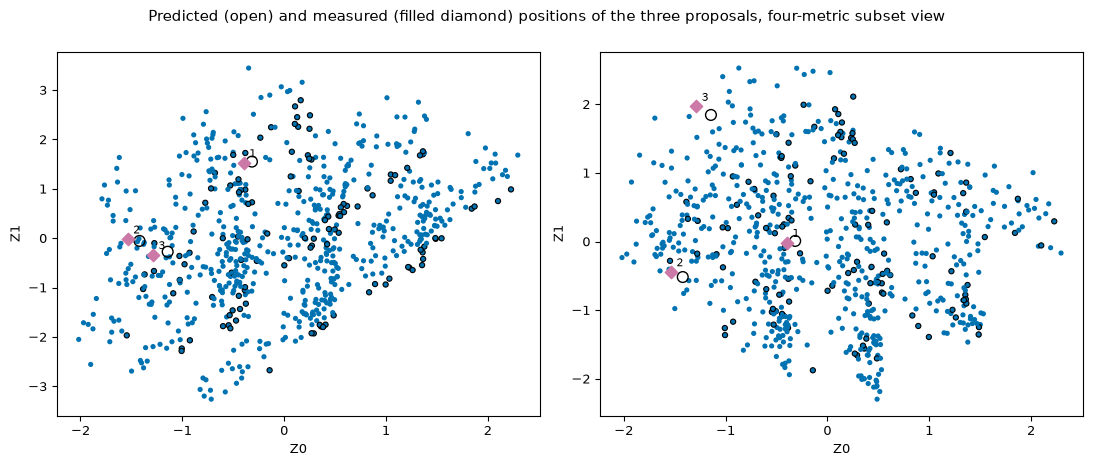

In [23]:
# CELL: predict-check-comparison
meas = checks[checks.role == "proposal"].reset_index(drop=True)
chart_m = reg.trade_space_.transform(meas[ATTR4].to_numpy(float))
Zm, lvm = chart_m[:, :-1], chart_m[:, -1]
band_r = 1 / tau_r
cmp_rows = []
for i, r in props.iterrows():
    zp = r[[c for c in props.columns if c.startswith("pred_z")]].to_numpy(float)
    dz = float(np.linalg.norm(Zm[i] - zp))
    dl = float(lvm[i] - r.pred_log_v)
    cmp_rows.append(
        {
            "proposal": r["name"],
            "predicted log V": r.pred_log_v,
            "measured log V": lvm[i],
            "difference": dl,
            "|diff| / band": abs(dl) / band_r,
            "log V within band": abs(dl) <= band_r,
            "||dZ||": dz,
            "||dZ|| / band": dz / band_r,
            "Z within band": dz <= band_r,
        }
    )
cmp = pd.DataFrame(cmp_rows)
print(f"band 1/tau = {band_r:.4f} (tau = {tau_r:.2f})")
print(cmp.to_string(index=False))
print("\nmeasured Z vs predicted Z (per coordinate):")
for i, r in props.iterrows():
    print(
        f"  {r['name']}: predicted {np.round(r[[c for c in props.columns if c.startswith('pred_z')]].to_numpy(float), 3)}, measured {np.round(Zm[i], 3)}"
    )
print("\npredicted versus measured attributes (difference in units of predict_std):")
meas_attr = meas[ATTR4].to_numpy(float)
pull = (meas_attr - mu_attr) / sd
pt = pd.DataFrame(
    np.column_stack([mu_attr, meas_attr, pull]),
    index=meas["name"],
    columns=[f"{SHORT[a]} {k}" for k in ("predicted", "measured", "z") for a in ATTR4],
)
print(pt.T.to_string())
tree = cKDTree(Z4)
nn_med = float(np.median(tree.query(Z4, k=2)[0][:, 1]))
d_meas = tree.query(Zm, k=1)[0] / nn_med
d_pred = tree.query(props[[f"pred_z{c + 1}" for c in range(3)]].to_numpy(), k=1)[0] / nn_med
print(
    f"\nwhite space: distance to the nearest training design in units of the median nearest-neighbour spacing ({nn_med:.3f}):"
)
print("  target holes (hole_score in the file):", np.round(props.hole_score.to_numpy(), 2))
print(
    "  predicted positions:",
    np.round(d_pred, 2),
    " measured positions:",
    np.round(d_meas, 2),
    "(above 2.0 = still a hole)",
)
print("\nflags of the measured proposals:")
print(
    meas[
        [
            "name",
            "settled",
            "momentum_ok",
            "power_ok",
            "dod_ok",
            "eclipse_reserve_wh",
            "torque_saturated_frac",
        ]
    ].to_string(index=False)
)
print("\nmeasured four-metric attributes:")
print(meas[["name", *ATTR4]].rename(columns=SHORT).to_string(index=False))
print(
    "\nnote: the four-metric trade space ignores the energy attributes, so it scores proposals whose eclipse reserve is non-positive;"
)
print("the ten-attribute fit cannot (log of a non-positive reserve).")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, cols in zip(axes, [(0, 1), (0, 2)], strict=True):
    plot_frontier_coordinates(
        Z4[:, list(cols)],
        logv4,
        band=band_r,
        targets=props[[f"pred_z{c + 1}" for c in cols]].to_numpy(),
        ax=ax,
    )
    ax.scatter(Zm[:, cols[0]], Zm[:, cols[1]], marker="D", s=40, color=MEASURED_COLOR, zorder=5)
    for i in range(3):
        ax.annotate(
            str(i + 1),
            (Zm[i, cols[0]], Zm[i, cols[1]]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )
fig.suptitle(
    "Predicted (open) and measured (filled diamond) positions of the three proposals, four-metric subset view",
    y=1.0,
)
save(fig, "08_predict_check")

**What the comparison shows, plainly.**

- *$\log V$ is inside the band for all three:* the measured value is lower than predicted by 0.021, 0.022 and 0.046 against a band of 0.065 (0.32, 0.34 and 0.71 of the band). All three differences have the same sign: the measured designs are slightly further from the frontier than predicted.
- *The position along the frontier is outside the band for all three:* the distance between predicted and measured $Z$ is 0.088, 0.144 and 0.201, or 1.35, 2.21 and 3.09 bands (about 0.5, 0.8 and 1.1 of the median spacing between neighbouring designs in the chart). The regressor placed the proposals in the right region but not within the band.
- *The attributes are within about 1.2 predicted standard deviations:* the largest differences are slew time of proposal 3 (31.4 s measured against 28.6 s predicted, 1.2 standard deviations) and total mass of proposal 3 (0.9). The pointing errors are all within 0.7 standard deviations.
- *The measured designs are still in white space* (distances to the nearest training design of 2.76, 2.03 and 4.18 median spacings; above 2.0 is a hole), proposal 2 only just.
- *Two of the three proposals are not feasible designs in the sense of section 2:* proposals 1 and 2 have `dod_ok` false, with eclipse reserves of $-2.1$ and $-2.0$ Wh (batteries of about 22 Wh leave no eclipse reserve). The four-metric trade space does not contain the energy attributes, so neither the regressor nor the hole search could know this. Proposal 3 (a large wheel, a 200 Wh battery, a fine tracker) is feasible.

The outcome is a mixed one. As a predictor of distance from the frontier, the regressor held within the band in this small test; as a predictor of position along it, it did not. Three points are too few to say more, and the Gaussian process was trained on the same box the proposals come from.


## 14 · The regime comparison

The primary dataset uses an aggressive gain box (Kp 0.2 to 2.0, Kd 0.3 to 1.5; median Kd/Kp 1.06), chosen so that the demanded torque exceeds every wheel's cap and the wheel is the bottleneck. The stock-gain dataset (median Kd/Kp 3.95) is the baseline. The identical pipeline, from conditioning through `select_temperature` at the same target to `tension_report`, is run on the baseline and set beside the primary in one table.


In [24]:
# CELL: regime-comparison
def run_regime(path):
    df = pd.read_csv(path)
    ok = df.settled & df.power_ok & df.momentum_ok & (df[ATTRS] > 0).all(axis=1)
    fe = df[ok].reset_index(drop=True)
    c = make_conditioner(ATTRS)
    Mr = c.fit_transform(fe)[[f"metrics__{a}" for a in ATTRS]].to_numpy()
    t, e = fit_space(Mr)
    r = tension_report(e, Mr)
    r_sp = tension_report(e, Mr, association="spearman")
    nr = np.abs(e.score_samples(Mr)) < r.band
    return dict(
        df=df,
        fe=fe,
        M=Mr,
        tau=t,
        est=e,
        rep=r,
        rep_sp=r_sp,
        near=nr,
        kdkp=float(np.median(df.Kd / df.Kp)),
    )


base = run_regime(DATA / "adcs_designs_cubesat.csv")
prim = dict(
    df=raw,
    fe=feasible,
    M=M,
    tau=tau,
    est=est,
    rep=rep,
    rep_sp=rep_s,
    near=near,
    kdkp=float(np.median(raw.Kd / raw.Kp)),
)
print(
    "read from data/adcs_designs_cubesat.csv (cached; stock-gain box) and run through the identical pipeline"
)

read from data/adcs_designs_cubesat.csv (cached; stock-gain box) and run through the identical pipeline


In [25]:
# CELL: tension-report-baseline
describe(base["rep"], names10, "baseline regime (stock gains), ten attributes")
near_b = base["near"]
print(
    "near-frontier designs by wheel class: "
    + ", ".join(
        f"{w} {int((near_b & (base['fe'].wheel_class.to_numpy() == w)).sum())}" for w in WHEELS
    )
)

TENSION REPORT: baseline regime (stock gains), ten attributes
n_lemma = 6 (6-lemma); near-frontier designs 103 (band 1/tau = 0.0240)
contending set at tau = inf: control effort 0.434, slew time 0.253, power margin 0.179, settling time 0.081, pointing error 0.040, eclipse reserve 0.013
working-tau exponents (above 1e-3): control effort 0.430, slew time 0.332, power margin 0.176, settling time 0.026, pointing error 0.024, eclipse reserve 0.013
near-frontier designs by wheel class: small 79, medium 23, large 1


                                           primary (aggressive gains)   baseline (stock gains)
                               dataset adcs_designs_cubesat_gains.csv adcs_designs_cubesat.csv
                          median Kd/Kp                           1.06                     3.95
   feasible n (small / medium / large)          706 (191 / 248 / 267)    780 (239 / 279 / 262)
       momentum failures, small wheels                          37.2%                    19.2%
              tau, frac_above_, n_eff_              38.1, 0.096, 16.2        41.7, 0.104, 14.5
     band 1/tau, near-frontier designs                     0.0262, 51              0.0240, 103
near-frontier (small / medium / large)                    20 / 25 / 6              79 / 23 / 1
      total mass in the contending set                            yes                       no
    working-tau exponent of total mass                          0.180                    0.000
             settling time, total mass            

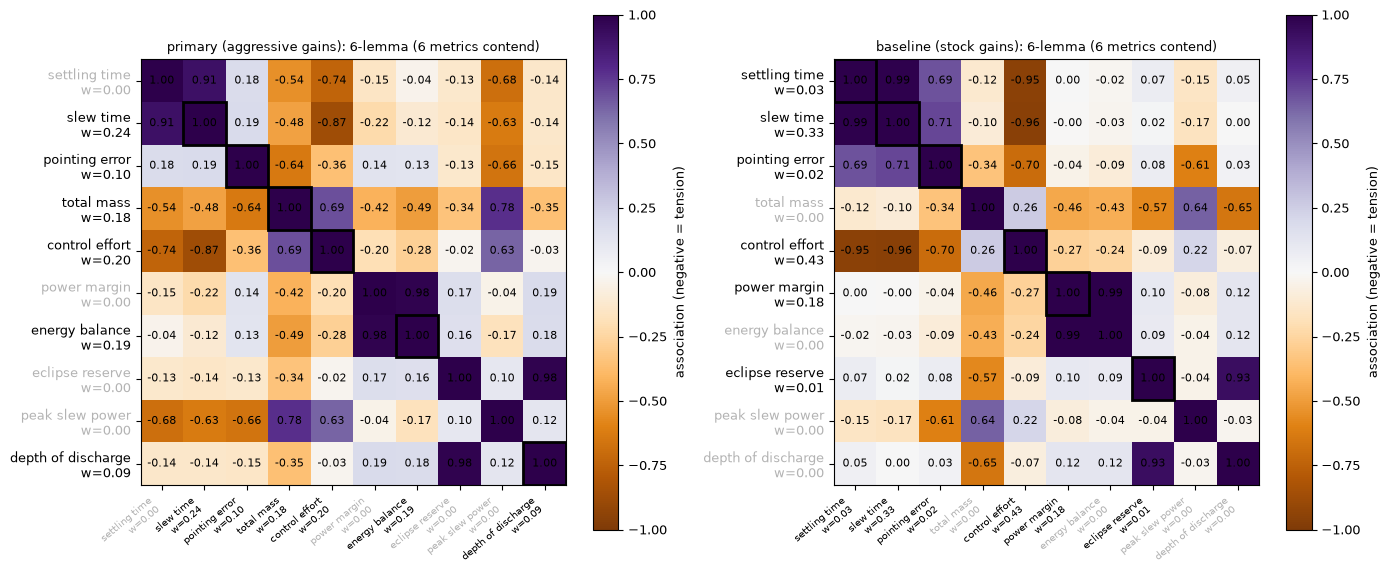

In [26]:
# CELL: regime-table
def row(label, f):
    return {"": label, "primary (aggressive gains)": f(prim), "baseline (stock gains)": f(base)}


def assoc(res, a, b):
    i, j = names10.index(a), names10.index(b)
    return f"{res['rep'].association[i, j]:+.2f} ({res['rep_sp'].association[i, j]:+.2f})"


def cset(res):
    r = res["rep"]
    return ", ".join(
        f"{names10[j]} {w:.2f}"
        for j, w in sorted(
            zip(r.contending_set, r.contending_exponents, strict=True), key=lambda t: -t[1]
        )
    )


rows = [
    row(
        "dataset",
        lambda r: "adcs_designs_cubesat_gains.csv" if r is prim else "adcs_designs_cubesat.csv",
    ),
    row("median Kd/Kp", lambda r: f"{r['kdkp']:.2f}"),
    row(
        "feasible n (small / medium / large)",
        lambda r: (
            f"{len(r['fe'])} ({' / '.join(str(int((r['fe'].wheel_class == w).sum())) for w in WHEELS)})"
        ),
    ),
    row(
        "momentum failures, small wheels",
        lambda r: f"{1 - r['df'][r['df'].wheel_class == 'small'].momentum_ok.mean():.1%}",
    ),
    row(
        "tau, frac_above_, n_eff_",
        lambda r: f"{r['tau']:.1f}, {r['est'].frac_above_:.3f}, {r['est'].n_eff_:.1f}",
    ),
    row(
        "band 1/tau, near-frontier designs",
        lambda r: f"{r['rep'].band:.4f}, {r['rep'].n_near_frontier}",
    ),
    row(
        "near-frontier (small / medium / large)",
        lambda r: " / ".join(
            str(int((r["near"] & (r["fe"].wheel_class.to_numpy() == w)).sum())) for w in WHEELS
        ),
    ),
    row(
        "total mass in the contending set",
        lambda r: "yes" if 3 in r["rep"].contending_set else "no",
    ),
    row("working-tau exponent of total mass", lambda r: f"{r['rep'].exponents[3]:.3f}"),
    row("settling time, total mass", lambda r: assoc(r, "settling time", "total mass")),
    row("slew time, total mass", lambda r: assoc(r, "slew time", "total mass")),
    row("pointing error, control effort", lambda r: assoc(r, "pointing error", "control effort")),
    row("settling time, pointing error", lambda r: assoc(r, "settling time", "pointing error")),
    row("slew time, control effort", lambda r: assoc(r, "slew time", "control effort")),
    row("settling time, slew time (aligned)", lambda r: assoc(r, "settling time", "slew time")),
    row(
        "median slew time / settling time",
        lambda r: f"{np.median(r['fe'].slew_time_s / r['fe'].settling_time_s):.2f}",
    ),
]
cmp_table = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 110, "display.width", 250):
    print(cmp_table.to_string(index=False))
print("\ncontending set at tau = inf, primary:  " + f"{prim['rep'].n_lemma}: " + cset(prim))
print("contending set at tau = inf, baseline: " + f"{base['rep'].n_lemma}: " + cset(base))
print(
    "\n(association: Pearson of oriented log-metrics among the near-frontier designs, Spearman in brackets)"
)
print(
    "principal direction 1 of the baseline:",
    ", ".join(
        f"{names10[j]} {base['rep'].tension_loadings[0][j]:+.2f}"
        for j in np.argsort(-np.abs(base["rep"].tension_loadings[0]))[:5]
    ),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, res, ttl in [
    (axes[0], prim, "primary (aggressive gains)"),
    (axes[1], base, "baseline (stock gains)"),
]:
    plot_tensions(res["rep"], names=names10, ax=ax)
    ax.set_title(ttl + ": " + ax.get_title(), fontsize=9)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right", fontsize=7)
save(fig, "09_regime_comparison")

**What the output shows.** With stock gains 780 of 1000 designs are feasible (small 239, medium 279, large 262), 19.2 % of the small-wheel designs fail momentum (37.2 % in the primary regime), $\tau=41.7$, and the contending set again has six members but is a different set: control effort 0.43, slew time 0.25, power margin 0.18, settling time 0.08, pointing error 0.04 and eclipse reserve 0.01. **Total mass is absent** (working-temperature exponent 0.000) and its associations with settling time and slew time are $-0.12$ and $-0.10$ against $-0.54$ and $-0.48$. Among the baseline's near-frontier designs 79 of 103 have small wheels and 1 has a large wheel, against 20, 25 and 6 of 51 in the primary regime. Pointing error with control effort is $-0.70$ and settling time with pointing error $+0.69$, against $-0.36$ and $+0.18$. The median slew time is 0.74 of the settling time against 0.60.

**Author's interpretation.** The two regimes differ in what limits arrival. With stock gains Kd/Kp is large, the loop's slow pole (a time constant of about $4K_d/K_p$ s) sets the time to settle and to arrive whatever the wheel can deliver, so a larger wheel buys no speed; settling and slew time then measure the same tail (ratio 0.74, association $+0.99$), and wheel class is a feasibility boundary only: a small wheel fails momentum, but nothing is traded for mass along the frontier. With the aggressive gains the wheel is the bottleneck, speed comes from the wheel, and wheel class is both a feasibility boundary and a frontier tension. The shape of the trade space depends on the operating regime: this is the main finding of the case, and it is conditional on the stiff-loop regime described in section 15.

*Next:* the limits of what has been shown.

In [27]:
# CELL: limits-numbers
feasible_idx = raw.index[alive]
cap = raw.usable_torque_nm < raw.groupby("wheel_class").usable_torque_nm.transform("max") - 1e-12
print(
    f"usable torque below the wheel maximum (torque capped by available power): {cap.mean():.1%} of the primary designs "
    f"({int(cap.sum())}; wheel classes {raw[cap].wheel_class.value_counts().to_dict()}), {cap[feasible_idx].mean():.1%} of the feasible set"
)
b = pd.read_csv(DATA / "adcs_designs_cubesat.csv")
capb = b.usable_torque_nm < b.groupby("wheel_class").usable_torque_nm.transform("max") - 1e-12
print(
    f"baseline: {capb.mean():.1%} of designs capped, wheel classes {b[capb].wheel_class.value_counts().to_dict()}"
)
print(
    f"power_ok true in {int(raw.power_ok.sum())} of {len(raw)} (primary) and {int(b.power_ok.sum())} of {len(b)} (baseline) designs"
)
print(
    f"power margin on the feasible set: {feasible.power_margin_w.min():.1f} to {feasible.power_margin_w.max():.1f} W (median {feasible.power_margin_w.median():.1f})"
)
print(
    f"unsettled (censored at the horizon) designs: {int((~raw.settled).sum())} of {len(raw)}; the feasible set contains settled designs only"
)
print(
    f"distinct ADCS (wheel plus tracker plus IMU) masses among {len(feasible)} feasible designs: {feasible.adcs_mass_kg.nunique()}"
)
print(
    f"feasible set: Kd/Kp quartiles {np.round(np.percentile(feasible.Kd / feasible.Kp, [25, 50, 75]), 2)}"
)

usable torque below the wheel maximum (torque capped by available power): 3.2% of the primary designs (32; wheel classes {'large': 32}), 3.5% of the feasible set
baseline: 3.2% of designs capped, wheel classes {'large': 32}
power_ok true in 1000 of 1000 (primary) and 1000 of 1000 (baseline) designs
power margin on the feasible set: 6.9 to 65.9 W (median 24.7)
unsettled (censored at the horizon) designs: 24 of 1000; the feasible set contains settled designs only
distinct ADCS (wheel plus tracker plus IMU) masses among 706 feasible designs: 9
feasible set: Kd/Kp quartiles [0.64 1.14 2.05]


## 15 · Limits and disclosures

Stated plainly, with this notebook's own values.

- **Hardware is stratified.** Wheels come in three classes, trackers in three grades, and masses are discrete (nine distinct ADCS masses among the 706 feasible designs). Gaps between strata in the chart are structural: a hole between a small and a large wheel may be a stratum, not an opportunity.
- **Times are censored.** Slew and settling times are censored at the 600 s horizon; the `settled` flag is used, and 24 designs that did not settle are excluded.
- **Values are illustrative.** The wheel, tracker, panel, battery and disturbance values are illustrative, not from datasheets, and the control-effort metric is a proxy.
- **The primary regime is a stiff-loop regime.** The aggressive gains were chosen so that the wheel is the bottleneck. In the WP4b record (computed there from the linearised loop, not recomputed in this notebook) a third of the designs are underdamped and 4.7 % have a damping ratio below 0.5. In the data, 37.2 % of small-wheel designs fail momentum.
- **Large wheels contribute few near-frontier designs.** 6 of the 51 near-frontier designs have large wheels.
- **Two margins are thin.** Pointing error with control effort is $-0.36$ (Spearman $-0.48$) against a threshold of $-0.30$, and settling time with pointing error is $+0.18$. The mass associations are $-0.54$ and $-0.48$ (Pearson), $-0.34$ and $-0.33$ (Spearman).
- **Power never limits a slew in this dataset.** The torque is capped by the available power in 3.2 % of the primary designs (all of them large wheels, with the smallest panels in the WP4b record; 3.5 % of the feasible set) and in 3.2 % of the baseline designs, `power_ok` is true for every design, and power reaches the controls only through mass and inertia. The power tensions are energy-sizing tensions, not power-limited slews.
- **The near-frontier samples are small.** 51 near-frontier designs of 706 (71 in the four-metric view) and an effective sample size of 16.2 at the chosen temperature; the per-class refits rest on 12 to 19.
- **The fit finds one facet.** A single monomial has constant exchange rates and finds one tension at the balanced point; regionally varying trades need the $K>1$ extension, which is documented and not built (`docs/limitations.md`).
- **Conditioning is a choice.** Section 8 shows the detail of the contending set depends on it.
- **A hole is not a verdict, and novelty is not preference.**


## 16 · Verification and validation

*Verify with the machine: did we build it right? Validate as a human: did we build the right thing?*

### What the machine verified

- **The package** is covered by the test suite (`uv run pytest`): the estimator, the preconditioner, the temperature selection, the tension report and the regressor, each against the derivation (`tests/test_matches_derivation.py`, `tests/test_estimator.py`, `tests/test_tensions.py`, `tests/test_predictive.py`, `tests/test_preconditioning.py`), the case model and datasets (`tests/test_cubesat_model.py`, `tests/test_adcs_enrichment.py`, `tests/test_check_designs.py`), and this notebook's structure (`tests/test_notebook.py`, which reads the committed notebook and does not execute it).
- **The lemmas** that the notebook leans on are derived symbolically in `derivation/` and run by the test suite: L1 (homogeneity of $V$ and the frontier), L2 (shift equivariance, used in section 8), L3 (the balance condition of the fit), L4 (convexity of the objective), L5 (soft maximum, temperature limits, used in section 4), L7 (elasticities and improvement factors, section 11), L8 (the chart $[Z\mid\log V]$, sections 6 and 13) and L9 (the pull-back, section 12).
- **In this notebook's own outputs:** the exponents sum to one; the inverse transform recovers the attributes; the pulled-back frontier agrees with `score_samples` to $10^{-15}$; the shift on all ten metrics leaves the report unchanged; the refit regressor reproduces the recorded predictions; the commit order of predictions and simulations is in the git history.
- **The conditions of the theory** that this case touches, by ledger tag, each with its failure mode:
  - **R1**, the balanced point lies in the relative interior of a facet with positive normal. It is what lets the exponents be read as exchange rates. If it fails (a vertex, an edge or a facet with a zero normal component) the exponents are not unique, some elasticities are undefined and the frontier reading degrades. The case does not certify R1; the contending set changing in detail in section 8 may be a sign that the balanced point sits near several facets, which this notebook does not test.
  - **A4**, the conditioning is log-affine and invertible. It makes the pull-back exact. If the conditioning is poorly chosen the exponents describe the conditioned metrics only, and a different conditioning answers a different question (section 8; the mass spread of section 3).
  - **F5** and **F10** are the symbols for the maximum in the proofs of the temperature limits (L5) and of the $K$-term limit (L10). They concern the proofs, and the failure mode is that a bound that is not attained would lose the lower squeeze. They do not constrain the case.
  - **The operating regime** is not a ledger condition but decides the finding: the wheel-class tension appears only when the loop is driven hard enough for the wheel to be the bottleneck (section 14).

### What remains for a human

The machine cannot do these; they are left to the reader.

1. **Look at figures 03 to 05 and judge them.** Does the black surface in figure 03 hug the upper envelope of the designs where it should, in the edge-on views as well as in the 3-D ones? In figure 04, are the wheel classes where physical intuition puts them? In figure 05, are the vermillion holes opportunities, or strata the hardware cannot occupy (a medium wheel with a fine tracker and a 12.7 kg bus)?
2. **Judge the explanations of section 9.** Each gives a mechanism and a design variable. Do they agree with your physical judgement of a cubesat attitude-control system, and is control effort the thing a designer pays for?
3. **Judge the conditioning.** Unit log-spread gives total mass a spread of 6.8 %. Is that how a designer weighs a kilogram against a second of slew time?
4. **Weigh the thin margins:** pointing error with control effort at $-0.36$ and the Spearman values near $-0.33$, on 51 near-frontier designs.
5. **Decide what the propose-predict-check miss means.** The position along the frontier missed the band by 1.4 to 3.1 bands, and two of three proposals fail the energy flag; is the test too small to say anything?
6. **Replace the illustrative hardware values** with datasheet values before any conclusion leaves the notebook.
7. **Decide whether the aggressive-gain regime is the regime of the mission.** The central finding is conditional on it.

The notebook stops here because the next step is yours: a tool computes a frontier, a person decides what it means.

### Sources and credit

Method and derivations: this repository (`docs/method.md`, `derivation/`). Interface conventions: [pedregosa2011scikit], [buitinck2013api]. The softmax-affine and geometric-programming form that the single monomial is the one-term case of: [hoburg2016data], [boyd2007tutorial]. The log-ratio coordinates of the chart: [egozcue2003isometric], [aitchison1983principal]. Multi-attribute trade-space exploration of space systems: [ross2004multi]. Presentation: [zargham2026derivations]. The cubesat model is the SysML v2 model `examples/adcs/cubesat_tradespace.sysml`, evaluated through opensysml, with the attitude simulation ported from the `adcs-lifecycle-demo` project (`docs/superpowers/notes/adcs-port.md`). Citation keys refer to `docs/references.bib`. The notebook claims the implementation and the case, not new terms: "novelty" is used only as the technical quantity $V-1$.

## Where to go from here

You have seen one case end to end. Start wherever suits you.

- **Derivations.** The mathematics behind every step is in [docs/method.md](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/method.md) (lemma tags L1 to L10 are the ones used above), the derivations are run by the test suite from [derivation/](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/tree/main/derivation), and the design record is the [specification](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/superpowers/specs/2026-11-07-posynomial-invariant-form-design.md).
- **Toolkit and API.** The package is `hyperbolic_trade_space` (class `HyperbolicTradeSpace`, scikit-learn conventions): [docs/api.md](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/api.md) for the interface and [docs/preconditioning.md](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/preconditioning.md) for the conditioning that decides what question is asked.
- **Limitations.** What the method does not do, and where it can mislead: [docs/limitations.md](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/limitations.md). Section 15 above applies it to this case.
- **The SysML model.** The cubesat the designs come from is a SysML v2 model, [examples/adcs/cubesat_tradespace.sysml](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/examples/adcs/cubesat_tradespace.sysml), with the extended design space in [extended_design_space.sysml](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/examples/adcs/extended_design_space.sysml).
- **Your own data.** Any table of designs with positive, comparable attributes works. The whole pipeline of this notebook, from a table to the tension report, is five lines once the orientations are chosen:

```python
from hyperbolic_trade_space import HyperbolicTradeSpace, LogAffinePreconditioner, select_temperature, tension_report

pre = LogAffinePreconditioner(orientation=[-1, -1, +1], scaler="standard")  # one entry per column
M = pre.fit_transform(your_table[["slew_time", "mass", "margin"]])
tau = select_temperature(M, target_frac_above=0.10, bounds=(3, 1e3))
est = HyperbolicTradeSpace(temperature=tau).fit(M)
print(tension_report(est, M).contending_set)  # column indices of the metrics that contend
```

Then read the output as this notebook did: the exponents first, the associations second, your own judgement last.

**Source and credit.** Repository: [https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space). Method page: [docs/method.md](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/method.md). Specification: [docs/superpowers/specs/2026-11-07-posynomial-invariant-form-design.md](https://github.com/DynamicalSystemsGroup/hyperbolic-trade-space/blob/main/docs/superpowers/specs/2026-11-07-posynomial-invariant-form-design.md). Dynamical Systems Group.
